In [1]:
from pathlib import Path
import collections.abc
import gc
import importlib.util
import json
import csv
import logging
import os
import re
import shutil
import subprocess
import sys
import uuid
import zipfile

os.environ.pop("CUDA_LAUNCH_BLOCKING", None)
import torch

if not torch.cuda.is_available():
    raise RuntimeError("Enable a Kaggle GPU before running this notebook.")
if torch.distributed.is_initialized():
    raise RuntimeError("Restart the kernel: this notebook uses one GPU, not DDP.")
torch.cuda.set_device(0)
torch.set_num_threads(min(2, os.cpu_count() or 2))

WORK = OUT = Path("/kaggle/working/result_mgn")
RUNTIME = Path("/kaggle/working/_osnet_mgn_runtime")
KAGGLE_INPUT = Path("/kaggle/input")
RESULT_ZIP = Path("/kaggle/working/result_mgn.zip")
RUN_MODE = "resume"                  # Continuation only; never initialize new heads or restart at epoch 1.
TARGET_MGN_EPOCHS = 30                # Total MGN target. Resume at any saved stage epoch (0-30); stop at total epoch 120.
RESTORE_BUNDLE = ""                  # Optional result_mgn.zip; includes latest, best, sources and split.
RESUME_CHECKPOINT = ""               # Empty: select the newest saved MGN training checkpoint in Output or Input. Explicit .pth overrides.
CONFIG_PATH = ""                     # Optional explicit mevid_osnet.yml.
SOURCE_BEST_CHECKPOINT = ""          # Only needed if sources/osnet_best_before_mgn.pth is absent.

FROZEN_OSNET_STAGES = ()
DATALOADER_PREFETCH = 2
IMAGE_READ_THREADS = 4
CACHE_TRAIN_IMAGES = True
IMAGE_CACHE_RAM_GIB = 2.0
CHECKPOINT_INTERVAL_MINUTES = 10.0
AUTO_BUNDLE = True                   # Refresh result_mgn.zip after timed/post-validation saves.
KEEP_PERIODIC_CHECKPOINTS = False    # Latest + best + final are normally sufficient.
LOG_EVERY = 20
HEALTH_CHECK_EVERY = 100
MIN_TRAIN_SAMPLES = 1000
TRAINING_REVISION = "osnet_mgn_stage_v1"  # Unchanged: existing MGN checkpoints remain compatible.

EVAL_BATCH_SIZE = 64
EVAL_NUM_WORKERS = 4
EVAL_READ_THREADS = 4
EVAL_PREFETCH_FACTOR = 2
EVAL_QUERY_CHUNK_SIZE = 128
REUSE_EVAL_RESULTS = True

# Use an independent manifest to retain the original complete final test.
# Otherwise preserve the previous CUSTOM identity-disjoint 20% / 80% holdout.
VALIDATION_MANIFEST = ""             # JSON: {"query": [[path, raw_pid, cam0], ...], "gallery": [...]}
VALIDATION_ID_FRACTION = 0.20
VALIDATION_SPLIT_SEED = 42
VALIDATION_CACHE_RAM_GIB = 0.5
# No pre-training checkpoint sweep. Validate immediately after each new stage epoch.
# Restore the existing MGN split and best score; do not re-evaluate old checkpoints first.

assert RUN_MODE == "resume" and TARGET_MGN_EPOCHS > 0
assert set(FROZEN_OSNET_STAGES) <= {"conv1", "conv2", "conv3", "conv4", "conv5"}
assert len(set(FROZEN_OSNET_STAGES)) == len(FROZEN_OSNET_STAGES)
assert EVAL_BATCH_SIZE > 0 and EVAL_NUM_WORKERS >= 0 and EVAL_QUERY_CHUNK_SIZE > 0
assert DATALOADER_PREFETCH > 0 and IMAGE_READ_THREADS > 0 and EVAL_READ_THREADS > 0
assert IMAGE_CACHE_RAM_GIB >= 0 and VALIDATION_CACHE_RAM_GIB >= 0
assert CHECKPOINT_INTERVAL_MINUTES >= 0 and LOG_EVERY > 0 and HEALTH_CHECK_EVERY > 0
WORK.mkdir(parents=True, exist_ok=True)
RUNTIME.mkdir(parents=True, exist_ok=True)
MODEL_READY = False
TRAINING_STATE = FINAL_METRICS = SOURCE_PROVENANCE = None
print(f"GPU: {torch.cuda.get_device_name(0)} | Mode: {RUN_MODE} | Results: {OUT}")


GPU: Tesla T4 | Mode: resume | Results: /kaggle/working/result_mgn


In [2]:
# Result bundle: no dataset, package cache, repository clone, or temporary files.
from pathlib import PurePosixPath
import stat


def restore_result_bundle(path):
    """Restore one portable result_mgn/ folder without replacing an active training run."""
    source = Path(path).expanduser().resolve()
    if not source.is_file():
        raise FileNotFoundError(source)
    if any(OUT.rglob("*.pth")):
        raise RuntimeError("Output already contains checkpoints; do not overwrite it with a ZIP.")
    with zipfile.ZipFile(source) as archive:
        members = []
        total_bytes = 0
        for member in archive.infolist():
            relative = PurePosixPath(member.filename)
            if (relative.is_absolute() or ".." in relative.parts or "\\" in member.filename
                    or not relative.parts or relative.parts[0] != "result_mgn"):
                raise ValueError(f"Unsafe or unsupported ZIP member: {member.filename}")
            if stat.S_ISLNK(member.external_attr >> 16):
                raise ValueError("Symbolic links are not accepted in result bundles.")
            if member.flag_bits & 1:
                raise ValueError("Encrypted result bundles are not supported.")
            target = OUT.joinpath(*relative.parts[1:])
            if not target.resolve().is_relative_to(OUT.resolve()):
                raise ValueError("ZIP path leaves result_mgn/.")
            total_bytes += member.file_size
            members.append((member, target))
        if not any(m.filename.endswith(".pth") for m, _ in members):
            raise ValueError("This ZIP does not contain any checkpoint.")
        if total_bytes + 256 * 1024**2 > shutil.disk_usage(OUT).free:
            raise RuntimeError("Insufficient disk space to restore result_mgn.zip.")
        # Validate before writing; preserve conflicting existing non-checkpoint files.
        for member, target in members:
            if target.is_file() and not member.is_dir():
                if target.read_bytes() != archive.read(member):
                    raise RuntimeError(f"Restore destination already contains different data: {target}")
        for member, target in members:
            if member.is_dir():
                target.mkdir(parents=True, exist_ok=True)
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                temporary = target.with_name("." + target.name + ".restore.tmp")
                try:
                    with archive.open(member) as src, temporary.open("wb") as dst:
                        shutil.copyfileobj(src, dst, length=1024 * 1024)
                    os.replace(temporary, target)
                finally:
                    temporary.unlink(missing_ok=True)
    print("Restored:", source, "->", OUT, flush=True)


def make_result_bundle():
    """Refresh a single download atomically; never alter the checkpoint marker."""
    if not any(OUT.glob("*.pth")):
        raise RuntimeError("No checkpoint has been saved yet.")
    temporary = RESULT_ZIP.with_name("." + RESULT_ZIP.name + ".tmp")
    excluded = {"__pycache__", "previous_runs", ".git", "fast-reid", "runtime"}
    try:
        with zipfile.ZipFile(temporary, "w", compression=zipfile.ZIP_STORED) as archive:
            for directory, subdirs, names in os.walk(OUT):
                subdirs[:] = [name for name in subdirs if name not in excluded]
                for name in sorted(names):
                    path = Path(directory) / name
                    if path.is_symlink() or name.endswith((".tmp", ".part", ".zip")):
                        continue
                    if not path.is_file():
                        continue
                    archive.write(path, str(Path("result_mgn") / path.relative_to(OUT)))
        os.replace(temporary, RESULT_ZIP)
    finally:
        temporary.unlink(missing_ok=True)
    print(f"Bundle ready: {RESULT_ZIP} ({RESULT_ZIP.stat().st_size / 1024**2:.1f} MiB)", flush=True)
    return RESULT_ZIP


if RESTORE_BUNDLE:
    restore_result_bundle(RESTORE_BUNDLE)
elif not any(OUT.glob("model_*.pth")):
    bundles = [RESULT_ZIP] if RESULT_ZIP.is_file() else sorted(KAGGLE_INPUT.rglob("result_mgn*.zip"))
    if len(bundles) > 1:
        raise RuntimeError("Several MGN bundles found; set RESTORE_BUNDLE explicitly.")
    if bundles:
        restore_result_bundle(bundles[0])
print("MGN outputs:", OUT, "| Previous OSNet result/ is never overwritten.")


MGN outputs: /kaggle/working/result_mgn | Previous OSNet result/ is never overwritten.


In [3]:
# Kaggle inputs

def find_mevid_root(input_root=KAGGLE_INPUT):
    required = ("bbox_train", "bbox_test", "mevid-v1-annotation-data")
    preferred = input_root / "mevid-sample" / "MEVID_Sample_Dataset"
    if all((preferred / name).is_dir() for name in required):
        return preferred.resolve()
    for annotation_dir in input_root.rglob("mevid-v1-annotation-data"):
        candidate = annotation_dir.parent
        if all((candidate / name).is_dir() for name in required):
            return candidate.resolve()
    raise FileNotFoundError("Attach the MEVID dataset to Kaggle Input.")


MEVID_ROOT = find_mevid_root()
DATA_DIRS = {
    "bbox_train": str(MEVID_ROOT / "bbox_train"),
    "bbox_test": str(MEVID_ROOT / "bbox_test"),
    "annotation": str(MEVID_ROOT / "mevid-v1-annotation-data"),
}
for filename in ("train_name.txt", "test_name.txt", "track_train_info.txt",
                 "track_test_info.txt", "query_IDX.txt"):
    path = Path(DATA_DIRS["annotation"]) / filename
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(f"Missing or empty annotation: {path}")
print("MEVID input:", MEVID_ROOT)


MEVID input: /kaggle/input/datasets/quangnguyen97/mevid-sample/MEVID_Sample_Dataset


In [4]:
# Dependencies

FASTREID_REPOSITORY = "https://github.com/JDAI-CV/fast-reid.git"
FASTREID_COMMIT = "c9bc3ceb2f7a6438b62fb515ea3df6d1e999e95d"
FASTREID_ROOT = RUNTIME / "fast-reid"

REQUIRED_PACKAGES = {
    "yacs": "yacs",
    "termcolor": "termcolor",
    "prettytable": "prettytable",
    "easydict": "easydict",
    "gdown": "gdown",
    "faiss": "faiss-cpu",
    "tensorboard": "tensorboard",
    "tabulate": "tabulate",
    "tqdm": "tqdm",
    "sklearn": "scikit-learn",
    "yaml": "PyYAML",
    "scipy": "scipy",
}

def run_command(*args):
    return subprocess.run(args, check=True, text=True, capture_output=True)

def install_missing_packages():
    missing = [
        package
        for module, package in REQUIRED_PACKAGES.items()
        if importlib.util.find_spec(module) is None
    ]
    if missing:
        print("Installing:", ", ".join(missing))
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "--quiet", *missing],
            check=True,
        )

def prepare_fastreid():
    if not (FASTREID_ROOT / ".git").is_dir():
        FASTREID_ROOT.parent.mkdir(parents=True, exist_ok=True)
        subprocess.run(
            ["git", "clone", "--quiet", FASTREID_REPOSITORY, str(FASTREID_ROOT)],
            check=True,
        )

    try:
        run_command("git", "-C", str(FASTREID_ROOT), "cat-file", "-e", f"{FASTREID_COMMIT}^{{commit}}")
    except subprocess.CalledProcessError:
        subprocess.run(
            ["git", "-C", str(FASTREID_ROOT), "fetch", "--quiet", "origin", FASTREID_COMMIT],
            check=True,
        )

    run_command("git", "-C", str(FASTREID_ROOT), "checkout", "--quiet", "--detach", FASTREID_COMMIT)
    actual_commit = run_command(
        "git", "-C", str(FASTREID_ROOT), "rev-parse", "HEAD"
    ).stdout.strip()
    if actual_commit != FASTREID_COMMIT:
        raise RuntimeError(f"FastReID revision mismatch: {actual_commit}")

    root_string = str(FASTREID_ROOT)
    if root_string not in sys.path:
        sys.path.insert(0, root_string)
    return actual_commit

install_missing_packages()
FASTREID_VERSION = prepare_fastreid()
for alias in ("Mapping", "MutableMapping", "Sequence", "Iterable"):
    if not hasattr(collections, alias):
        setattr(collections, alias, getattr(collections.abc, alias))
os.environ["FASTREID_DATASETS"] = str(MEVID_ROOT)
os.environ["TORCH_HOME"] = str(WORK / "weights" / "torch")
print("FastReID root:", FASTREID_ROOT)
print("FastReID commit:", FASTREID_VERSION)

from tqdm.auto import tqdm


Installing: yacs, faiss-cpu
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 85.6 MB/s eta 0:00:00
FastReID root: /kaggle/working/_osnet_mgn_runtime/fast-reid
FastReID commit: c9bc3ceb2f7a6438b62fb515ea3df6d1e999e95d


In [5]:
# MeViD splits

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

def build_image_index(root):
    root = Path(root)
    index = {}
    duplicates = set()
    image_count = 0
    print(f"Indexing images in: {root}")

    for dirpath, _, filenames in os.walk(root):
        directory = Path(dirpath)
        for filename in filenames:
            if os.path.splitext(filename)[1].casefold() not in IMAGE_EXTENSIONS:
                continue
            image_count += 1
            path = directory / filename
            if filename in index and index[filename] != path:
                duplicates.add(filename)
            else:
                index[filename] = path

    for filename in duplicates:
        index.pop(filename, None)
    print(
        f"Found {image_count:,} images; indexed {len(index):,} unique filenames "
        f"({len(duplicates):,} duplicate names ignored)"
    )
    return index, image_count

def split_summary(samples):
    identities = {sample[1] for sample in samples}
    cameras = {sample[2] for sample in samples}
    return {"images": len(samples), "identities": len(identities),
            "cameras": len(cameras),
            "avg_images_per_identity": len(samples) / max(len(identities), 1)}

def load_mevid_splits(data_dirs):
    """Join attached images to tracklets in one sequential annotation pass."""
    annotations = Path(data_dirs["annotation"])
    image_roots = {"train": Path(data_dirs["bbox_train"]),
                   "test": Path(data_dirs["bbox_test"])}
    indexed = {subset: build_image_index(root) for subset, root in image_roots.items()}
    image_indexes = {subset: value[0] for subset, value in indexed.items()}
    image_counts = {subset: value[1] for subset, value in indexed.items()}
    if not all(image_counts.values()):
        raise RuntimeError("An attached MEVID image directory is empty")

    # Preserve zero-based query tracklet rows from the supplied notebook.
    query_rows = {int(float(value)) for value in
                  (annotations / "query_IDX.txt").read_text().split()}
    splits = {"train": [], "query": [], "gallery": []}
    stats = {}
    for subset in ("train", "test"):
        image_lookup = image_indexes[subset]
        track_path = annotations / f"track_{subset}_info.txt"
        tracks = []
        for row, line in enumerate(track_path.read_text().splitlines()):
            values = line.split()
            if len(values) < 5:
                raise ValueError(f"Invalid {subset} tracklet row {row}: {line}")
            start, end, pid, outfit, camera = map(lambda x: int(float(x)), values[:5])
            if start > end + 1:
                raise ValueError(f"Invalid bounds on {subset} tracklet row {row}")
            tracks.append((start, end, pid, camera, row))
        if subset == "test" and query_rows and max(query_rows) >= len(tracks):
            raise ValueError("query_IDX.txt contains a row outside track_test_info.txt")

        if any(tracks[i][0] > tracks[i+1][0] or
               tracks[i][1] >= tracks[i+1][0]
               for i in range(len(tracks)-1)):
            raise RuntimeError(f"{subset} track ranges are not ordered / overlap")
        found = set()
        track_idx = 0
        annotation_count = 0
        with (annotations / f"{subset}_name.txt").open("r") as names_file:
            for idx, line in enumerate(names_file):
                annotation_count += 1
                filename = line.strip()
                image = image_lookup.get(filename)
                if image is None:
                    continue
                while track_idx < len(tracks) and idx > tracks[track_idx][1]:
                    track_idx += 1
                if track_idx >= len(tracks) or idx < tracks[track_idx][0]:
                    raise RuntimeError(f"Attached {subset} image has no track: {filename}")
                _, _, pid, camera, row = tracks[track_idx]
                if pid == -1:
                    continue
                dest = "train" if subset == "train" else ("query" if row in query_rows else "gallery")
                splits[dest].append((str(image), pid, camera - 1))
                found.add(filename)

        unmatched = set(image_lookup) - found
        if unmatched:
            examples = sorted(unmatched)[:8]
            raise RuntimeError(
                f"{len(unmatched):,} attached {subset} images could not be matched "
                f"to a valid annotation track (first: {examples}). "
                "Check dataset/annotation versions and PID=-1 entries."
            )
        stats[subset] = {"annotation_filenames": annotation_count,
                         "tracklets": len(tracks),
                         "attached_images": image_counts[subset],
                         "matched_images": len(found)}
        print(f"{subset}: matched {len(found):,}/{image_counts[subset]:,} existing images "
              f"using {len(tracks):,} tracklets")

    stats["splits"] = {name: split_summary(samples)
                       for name, samples in splits.items()}
    for name, summary in stats["splits"].items():
        if not summary["images"]:
            raise RuntimeError(f"MEVID {name} split is empty")
    if stats["splits"]["train"]["images"] < MIN_TRAIN_SAMPLES:
        raise RuntimeError("MEVID training split is unexpectedly small")
    query_ids = {sample[1] for sample in splits["query"]}
    gallery_ids = {sample[1] for sample in splits["gallery"]}
    if not query_ids.issubset(gallery_ids):
        raise RuntimeError(f"{len(query_ids-gallery_ids)} query identities absent from gallery")
    print("\nMEVID split summary:\n", json.dumps(stats, indent=2))
    return splits, stats, image_counts

split_cache_key = tuple(sorted(DATA_DIRS.items()))
if globals().get("_MEVID_SPLIT_CACHE_KEY") != split_cache_key or "SPLITS" not in globals():
    SPLITS, SPLIT_STATS, IMAGE_COUNTS = load_mevid_splits(DATA_DIRS)
    _MEVID_SPLIT_CACHE_KEY = split_cache_key
else:
    print("Reusing prepared MEVID train/query/gallery metadata")

TRAIN_IMAGE_COUNT = IMAGE_COUNTS["train"]
TEST_IMAGE_COUNT = IMAGE_COUNTS["test"]
DATASET_NAME = "MEVID_OSNet"

NUM_TRAIN_IDENTITIES = SPLIT_STATS["splits"]["train"]["identities"]

# Compute the portable sample-order fingerprint once after split preparation.
import hashlib
TRAINING_SAMPLE_SHA256 = hashlib.sha256(json.dumps(
    [(Path(p).name, int(pid), int(cam)) for p, pid, cam in SPLITS["train"]],
    sort_keys=True, ensure_ascii=False, allow_nan=False).encode("utf-8")).hexdigest()


Indexing images in: /kaggle/input/datasets/quangnguyen97/mevid-sample/MEVID_Sample_Dataset/bbox_train
Found 182,000 images; indexed 182,000 unique filenames (0 duplicate names ignored)
Indexing images in: /kaggle/input/datasets/quangnguyen97/mevid-sample/MEVID_Sample_Dataset/bbox_test
Found 59,645 images; indexed 59,645 unique filenames (0 duplicate names ignored)
train: matched 182,000/182,000 existing images using 6,339 tracklets
test: matched 59,645/59,645 existing images using 1,754 tracklets

MEVID split summary:
 {
  "train": {
    "annotation_filenames": 3609156,
    "tracklets": 6339,
    "attached_images": 182000,
    "matched_images": 182000
  },
  "test": {
    "annotation_filenames": 1186251,
    "tracklets": 1754,
    "attached_images": 59645,
    "matched_images": 59645
  },
  "splits": {
    "train": {
      "images": 182000,
      "identities": 104,
      "cameras": 22,
      "avg_images_per_identity": 1750.0
    },
    "query": {
      "images": 10328,
      "identitie

In [6]:
# YAML configuration

import yaml
from fastreid.config import get_cfg, CfgNode as CN


def new_mgn_cfg():
    config = get_cfg()
    if "SEED" not in config:
        config.SEED = 42
    config.MODEL.MGN = CN()
    config.MODEL.MGN.PARTS = [2, 3]
    config.MODEL.MGN.PART_DIM = 256
    config.MODEL.MGN.LOCAL_CE_WEIGHT = 1.0
    config.MODEL.MGN.PART_TRIPLET_WEIGHT = 1.0
    config.MODEL.MGN.INFERENCE_GROUP_WEIGHTS = [1.0, 1.0, 1.0]
    config.MODEL.MGN.HEAD_WARMUP_EPOCHS = 1
    return config


CONFIG_FILENAMES = ("mevid_osnet.yml", "Base-bagtricks.yml")


def find_config_pair(input_root=KAGGLE_INPUT):
    if CONFIG_PATH:
        config_file = Path(CONFIG_PATH).expanduser()
        base_file = config_file.parent / CONFIG_FILENAMES[1]
        if not config_file.is_file() or not base_file.is_file():
            raise FileNotFoundError("CONFIG_PATH must point to mevid_osnet.yml beside Base-bagtricks.yml")
        return config_file.resolve(), base_file.resolve()
    restored = WORK / "config"
    if all((restored / name).is_file() for name in CONFIG_FILENAMES):
        return tuple(restored / name for name in CONFIG_FILENAMES)
    pairs = [
        (path.resolve(), (path.parent / CONFIG_FILENAMES[1]).resolve())
        for path in sorted(input_root.rglob(CONFIG_FILENAMES[0]))
        if (path.parent / CONFIG_FILENAMES[1]).is_file()
    ]
    pairs = [pair for pair in pairs if yaml.safe_load(pair[0].read_text()).get("MODEL", {}).get("META_ARCHITECTURE") == "OSNetMGN"]
    preferred = [pair for pair in pairs if any(
        part.lower().replace("_", "").replace("-", "") == "osnetconfig"
        for part in pair[0].parts
    )]
    candidates = preferred or pairs
    if not candidates:
        raise FileNotFoundError(
            "Attach the osnet_config dataset containing mevid_osnet.yml and "
            "Base-bagtricks.yml in the same directory."
        )
    if len(candidates) != 1:
        raise RuntimeError("Several config pairs found. Set CONFIG_PATH to the intended mevid_osnet.yml: "
                           + str([str(pair[0]) for pair in candidates]))
    return candidates[0]


def stage_config_files():
    source_config, source_base = find_config_pair()
    work_dir = WORK / "config"
    work_dir.mkdir(parents=True, exist_ok=True)
    config_file = work_dir / CONFIG_FILENAMES[0]
    base_file = work_dir / CONFIG_FILENAMES[1]
    if source_config.resolve() != config_file.resolve():
        shutil.copy2(source_config, config_file)
    if source_base.resolve() != base_file.resolve():
        shutil.copy2(source_base, base_file)
    return source_config, source_base, config_file, base_file

def validate_config(config, train_size):
    if (config.MODEL.META_ARCHITECTURE != "OSNetMGN"
            or config.SOLVER.OPT != "AdamW" or config.SOLVER.SCHED != "MultiStepLR"):
        raise ValueError("Use the saved OSNetMGN / AdamW / MultiStepLR configuration.")
    batch, instances = int(config.SOLVER.IMS_PER_BATCH), int(config.DATALOADER.NUM_INSTANCE)
    if instances < 1 or batch < 2 * instances or batch % instances or batch > train_size:
        raise ValueError("Use a valid identity-balanced batch with at least two identities.")
    if not 0 <= int(config.MODEL.MGN.HEAD_WARMUP_EPOCHS) < int(config.SOLVER.MAX_EPOCH):
        raise ValueError("Head warmup must be shorter than the total MGN stage.")
    if config.MODEL.FREEZE_LAYERS or int(config.SOLVER.FREEZE_ITERS) > 0:
        raise ValueError("Use FROZEN_OSNET_STAGES, not the native temporary-freeze wrapper.")
    if (config.SOLVER.CLIP_GRADIENTS.ENABLED
            and (config.SOLVER.CLIP_GRADIENTS.CLIP_TYPE != "norm"
                 or float(config.SOLVER.CLIP_GRADIENTS.CLIP_VALUE) <= 0)):
        raise ValueError("Global gradient clipping requires CLIP_TYPE=norm and a positive value.")

(
    CONFIG_SOURCE_FILE,
    BASE_CONFIG_SOURCE_FILE,
    CONFIG_FILE,
    BASE_CONFIG_FILE,
) = stage_config_files()

cfg = new_mgn_cfg()
cfg.merge_from_file(str(CONFIG_FILE))
cfg.defrost()
# Override restored 10-epoch YAML as well. Keep the existing LR milestones/optimizer.
cfg.SOLVER.MAX_EPOCH = int(TARGET_MGN_EPOCHS)

# Model weights are restored once in Initialization; no pretrained transfer on resume.
cfg.DATASETS.NAMES = (DATASET_NAME,)
cfg.DATASETS.TESTS = (DATASET_NAME,)
cfg.OUTPUT_DIR = str(OUT)
cfg.MODEL.DEVICE = "cuda:0"
cfg.MODEL.BACKBONE.PRETRAIN = False
cfg.MODEL.BACKBONE.PRETRAIN_PATH = ""
cfg.TEST.EVAL_PERIOD = 0  # Native hook disabled; our epoch loop validates explicitly.
validate_config(cfg, len(SPLITS["train"]))
cfg.freeze()

print("Source config:", CONFIG_SOURCE_FILE)
print("Source base:", BASE_CONFIG_SOURCE_FILE)
print(f"MGN stage target: {cfg.SOLVER.MAX_EPOCH} total epochs; resume restores the CURRENT learning rates.")
print(f"Train/test batch: {cfg.SOLVER.IMS_PER_BATCH}/{cfg.TEST.IMS_PER_BATCH} | "
      f"Workers: {cfg.DATALOADER.NUM_WORKERS} | AMP: {cfg.SOLVER.AMP.ENABLED}")
print("Head:", cfg.MODEL.HEADS.POOL_LAYER, "| Losses:", tuple(cfg.MODEL.LOSSES.NAME))
print(f"Saved warmup/scheduler state is retained; milestones: {list(cfg.SOLVER.STEPS)}.")
print("Validation: after every epoch; selection: General mAP. Final test: old OSNet Best vs MGN Best.")
print(f"Checkpoint: result_mgn/; periodic safety save about every {CHECKPOINT_INTERVAL_MINUTES:g} minutes.")


Source config: /kaggle/input/datasets/qimatx/osnet-config/mevid_osnet.yml
Source base: /kaggle/input/datasets/qimatx/osnet-config/Base-bagtricks.yml
MGN stage target: 30 total epochs; resume restores the CURRENT learning rates.
Train/test batch: 16/64 | Workers: 4 | AMP: False
Head: GlobalAvgPool | Losses: ('CrossEntropyLoss', 'TripletLoss')
Saved warmup/scheduler state is retained; milestones: [7, 9].
Validation: after every epoch; selection: General mAP. Final test: old OSNet Best vs MGN Best.
Checkpoint: result_mgn/; periodic safety save about every 10 minutes.


In [7]:
# Training imports and data loading

import random
import time
import warnings
from collections import OrderedDict
from types import SimpleNamespace

import numpy as np
import torch.nn.functional as F

from fastreid.data.datasets import DATASET_REGISTRY
from fastreid.data.datasets.bases import ImageDataset
from fastreid.engine import DefaultTrainer, default_setup, hooks
from fastreid.engine.train_loop import HookBase
from fastreid.modeling.meta_arch.baseline import Baseline
import fastreid.data.build as data_build

warnings.filterwarnings("ignore", message=r"TypedStorage is deprecated.*", category=UserWarning)


def log(*args, **kwargs):
    kwargs.setdefault("flush", True)
    print(*args, **kwargs)


def atomic_json(path, value):
    path = Path(path)
    temporary = path.with_name("." + path.name + ".tmp")
    try:
        temporary.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def notebook_data_loader(local_rank=0, **kwargs):
    workers = int(kwargs.get("num_workers", cfg.DATALOADER.NUM_WORKERS))
    kwargs.update(num_workers=workers, pin_memory=True)
    if workers > 0:
        # Kaggle/Linux workers decode and transform CPU images only.
        kwargs.update(persistent_workers=True, prefetch_factor=DATALOADER_PREFETCH,
                      multiprocessing_context="fork")
    dataset = kwargs.get("dataset")
    cache = globals().get("TRAIN_IMAGE_CACHE")
    if (cache is not None and getattr(dataset, "relabel", False)
            and hasattr(dataset, "img_items")):
        # The sampler and labels still come from FastReID. Only byte reads overlap.
        kwargs["dataset"] = BatchReadDataset(dataset, cache, IMAGE_READ_THREADS)
        kwargs["collate_fn"] = notebook_batch_collate
    return torch.utils.data.DataLoader(**kwargs)


def preprocess_on_model_device(self, batched_inputs):
    images = batched_inputs["images"] if isinstance(batched_inputs, dict) else batched_inputs
    if not torch.is_tensor(images):
        raise TypeError(f"Unsupported model input: {type(batched_inputs)}")
    images = images.to(self.device, non_blocking=True)
    return images.sub(self.pixel_mean).div(self.pixel_std)


if not hasattr(Baseline, "_kaggle_original_forward"):
    Baseline._kaggle_original_forward = Baseline.forward


def baseline_forward_with_device_targets(self, batched_inputs):
    if self.training and isinstance(batched_inputs, dict):
        targets = batched_inputs.get("targets")
        if torch.is_tensor(targets):
            batched_inputs = dict(batched_inputs)
            batched_inputs["targets"] = targets.to(self.device, non_blocking=True)
    return Baseline._kaggle_original_forward(self, batched_inputs)


data_build.DataLoaderX = notebook_data_loader
Baseline.preprocess_image = preprocess_on_model_device
Baseline.forward = baseline_forward_with_device_targets


class MEVID_OSNet(ImageDataset):
    def __init__(self, root=None, **kwargs):
        super().__init__(SPLITS["train"], SPLITS["query"], SPLITS["gallery"], **kwargs)


DATASET_REGISTRY._obj_map[DATASET_NAME] = MEVID_OSNet
print(f"Train: cuda:0 | batch {cfg.SOLVER.IMS_PER_BATCH} | "
      f"workers {cfg.DATALOADER.NUM_WORKERS} | AMP {cfg.SOLVER.AMP.ENABLED}")


Train: cuda:0 | batch 16 | workers 4 | AMP False


In [ ]:
# OSNet + MGN-style multi-granularity head. 
import math
from torch import nn
from fastreid.modeling.backbones import build_backbone
from fastreid.modeling.heads.embedding_head import EmbeddingHead
from fastreid.modeling.meta_arch.build import META_ARCH_REGISTRY
from fastreid.modeling.losses import cross_entropy_loss, triplet_loss, log_accuracy


class LocalPartHead(nn.Module):
    def __init__(self, channels, dimension, num_classes):
        super().__init__()
        self.projection = nn.Linear(channels, dimension, bias=False)
        self.bn = nn.BatchNorm1d(dimension)
        self.bn.bias.requires_grad_(False)
        self.weight = nn.Parameter(torch.empty(num_classes, dimension))
        nn.init.kaiming_normal_(self.projection.weight, mode="fan_out")
        nn.init.normal_(self.weight, std=0.01)

    def forward(self, vector):
        feature = self.projection(vector)
        neck = self.bn(feature)
        if not self.training:
            return neck
        logits = F.linear(neck, self.weight)
        return {"features": feature, "embedding": neck,
                "cls_outputs": logits, "pred_class_logits": logits}


class OSNetMGNHead(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.global_head = EmbeddingHead(config)
        self.parts = tuple(int(v) for v in config.MODEL.MGN.PARTS)
        channels = int(config.MODEL.BACKBONE.FEAT_DIM)
        dimension = int(config.MODEL.MGN.PART_DIM)
        classes = int(config.MODEL.HEADS.NUM_CLASSES)
        self.local_heads = nn.ModuleList(
            LocalPartHead(channels, dimension, classes) for _ in range(sum(self.parts)))
        self.embedding_dim = channels + sum(self.parts) * dimension
        self.group_weights = tuple(float(v) for v in config.MODEL.MGN.INFERENCE_GROUP_WEIGHTS)
        if len(self.group_weights) != 1 + len(self.parts) or min(self.group_weights) <= 0:
            raise ValueError("MGN inference needs a positive weight for each granularity.")

    @property
    def weight(self):
        # Keep the trainer's existing classifier diagnostics connected to the global branch.
        return self.global_head.weight

    def _combine(self, global_feature, local_features):
        groups = [F.normalize(global_feature, dim=1)]
        start = 0
        for parts in self.parts:
            group = torch.cat([F.normalize(f, dim=1)
                               for f in local_features[start:start + parts]], dim=1)
            groups.append(F.normalize(group, dim=1))
            start += parts
        # Equal default energy for global, 2-part and 3-part; not 5/6 weight on local parts.
        return F.normalize(torch.cat([g * math.sqrt(w) for g, w in
                                     zip(groups, self.group_weights)], dim=1), dim=1)

    def forward(self, feature_map, targets=None):
        if feature_map.ndim != 4 or feature_map.shape[2] < max(self.parts):
            raise ValueError("OSNet MGN requires a spatial NCHW map with enough vertical rows.")
        global_output = self.global_head(feature_map, targets)
        local_outputs, offset = [], 0
        for parts in self.parts:
            # Non-overlapping horizontal bins, preserving all spatial rows (also when H % parts != 0).
            for stripe in torch.tensor_split(feature_map, parts, dim=2):
                vector = stripe.mean(dim=(2, 3))
                local_outputs.append(self.local_heads[offset](vector))
                offset += 1
        if not self.training:
            return self._combine(global_output, local_outputs)
        groups, start = [], 0
        for parts in self.parts:
            groups.append(torch.cat([F.normalize(x["features"], dim=1)
                                     for x in local_outputs[start:start + parts]], dim=1))
            start += parts
        return {"features": self._combine(global_output["features"],
                                           [x["features"] for x in local_outputs]),
                "pred_class_logits": global_output["pred_class_logits"],
                "global_output": global_output, "local_outputs": local_outputs,
                "part_group_features": groups}


class OSNetMGN(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config.clone()
        self.backbone = build_backbone(config)
        self.heads = OSNetMGNHead(config)
        self.register_buffer("pixel_mean", torch.tensor(config.MODEL.PIXEL_MEAN).view(1, -1, 1, 1), persistent=False)
        self.register_buffer("pixel_std", torch.tensor(config.MODEL.PIXEL_STD).view(1, -1, 1, 1), persistent=False)
        self.branch_loss_components = {}

    @property
    def device(self):
        return self.pixel_mean.device

    def forward(self, inputs):
        images = inputs["images"] if isinstance(inputs, dict) else inputs
        images = images.to(self.device, non_blocking=True)
        # Out-of-place normalization: two models may read the same tensor during final evaluation.
        features = self.backbone((images - self.pixel_mean) / self.pixel_std)
        if not self.training:
            return self.heads(features)
        if not isinstance(inputs, dict) or "targets" not in inputs:
            raise ValueError("Training requires identity labels.")
        targets = inputs["targets"].to(self.device, non_blocking=True)
        output = self.heads(features, targets)
        loss_cfg, mgn = self.config.MODEL.LOSSES, self.config.MODEL.MGN
        global_output, local_outputs = output["global_output"], output["local_outputs"]
        log_accuracy(global_output["pred_class_logits"].detach(), targets)
        ce = lambda item: cross_entropy_loss(item["cls_outputs"], targets,
                                             loss_cfg.CE.EPSILON, loss_cfg.CE.ALPHA)
        global_ce = ce(global_output)
        local_ce = torch.stack([ce(item) for item in local_outputs]).mean()
        tri = lambda feat: triplet_loss(feat, targets, loss_cfg.TRI.MARGIN,
                                        loss_cfg.TRI.NORM_FEAT, loss_cfg.TRI.HARD_MINING)
        global_tri = tri(global_output["features"])
        part_tri = torch.stack([tri(feat) for feat in output["part_group_features"]]).mean()
        ce_weight, tri_weight = float(mgn.LOCAL_CE_WEIGHT), float(mgn.PART_TRIPLET_WEIGHT)
        self.branch_loss_components = {"ce_global": global_ce.detach(), "ce_parts": local_ce.detach(),
                                       "triplet_global": global_tri.detach(), "triplet_parts": part_tri.detach()}
        return {"loss_cls": (global_ce + ce_weight * local_ce) / (1 + ce_weight) * loss_cfg.CE.SCALE,
                "loss_triplet": (global_tri + tri_weight * part_tri) / (1 + tri_weight) * loss_cfg.TRI.SCALE}


# Re-executing this definition cell replaces only the registry class, not any trained weights.
META_ARCH_REGISTRY._obj_map["OSNetMGN"] = OSNetMGN
print("Registered OSNetMGN: global 512-D + five local 256-D parts = 1792-D (default).")


Registered OSNetMGN: global 512-D + five local 256-D parts = 1792-D (default).


In [ ]:
import io
from concurrent.futures import ThreadPoolExecutor

from torch.utils.data import Dataset, default_collate
from fastreid.utils.file_io import NativePathHandler, PathManager


def _read_original_image_bytes(path):
    try:
        return Path(path).read_bytes()
    except OSError as error:
        raise OSError(f"Cannot read training image {path}: {error}") from error


class OnDemandImageCache:
    """Cache exact image bytes, lazily; never scan or preload the dataset."""

    def __init__(self, max_bytes):
        self.max_bytes = int(max_bytes)
        if self.max_bytes < 0:
            raise ValueError("Image cache max_bytes must be non-negative.")
        self._pid = os.getpid()
        self._entries = OrderedDict()
        self._batch_payloads = {}
        self._reader_pool = None
        self._reader_threads = 0
        self.bytes_used = self.hits = self.misses = 0

    def _ensure_process(self):
        if self._pid != os.getpid():
            # Never use an executor inherited through fork.
            self.__init__(self.max_bytes)

    def close(self):
        if self._reader_pool is not None and self._pid == os.getpid():
            self._reader_pool.shutdown(wait=True, cancel_futures=True)
        self.__init__(self.max_bytes)

    def __getstate__(self):
        return {"max_bytes": self.max_bytes}

    def __setstate__(self, state):
        self.__init__(state["max_bytes"])

    def _remember(self, key, payload):
        size = len(payload)
        if 0 < size <= self.max_bytes:
            old = self._entries.pop(key, None)
            if old is not None:
                self.bytes_used -= len(old)
            while self.bytes_used + size > self.max_bytes:
                _, evicted = self._entries.popitem(last=False)
                self.bytes_used -= len(evicted)
            self._entries[key] = payload
            self.bytes_used += size

    def read_bytes(self, path):
        self._ensure_process()
        key = str(path)
        # Batch-local references avoid reopening files even with a tiny LRU limit.
        if key in self._batch_payloads:
            return self._batch_payloads[key]
        cached = self._entries.pop(key, None)
        if cached is not None:
            self._entries[key] = cached
            self.hits += 1
            return cached
        self.misses += 1
        payload = _read_original_image_bytes(key)
        self._remember(key, payload)
        return payload

    def begin_batch(self, paths, reader_threads):
        """Read only the requested batch; cache mutation stays in one thread."""
        self._ensure_process()
        if self._batch_payloads:
            raise RuntimeError("The previous image batch was not released.")
        started = time.perf_counter()
        paths = list(dict.fromkeys(str(path) for path in paths))
        payloads, missing = {}, []
        for key in paths:
            if key in self._entries:
                payloads[key] = self._entries[key]
                self._entries.move_to_end(key)
            else:
                missing.append(key)
        hits = len(paths) - len(missing)
        self.hits += hits
        self.misses += len(missing)
        threads = max(1, int(reader_threads))
        try:
            if threads > 1 and len(missing) > 1:
                if self._reader_pool is None or self._reader_threads != threads:
                    if self._reader_pool is not None:
                        self._reader_pool.shutdown(wait=True, cancel_futures=True)
                    self._reader_pool = ThreadPoolExecutor(
                        max_workers=threads, thread_name_prefix="osnet-image-read"
                    )
                    self._reader_threads = threads
                # The pool only returns bytes. It does not touch RNG, PIL, or CUDA.
                source = self._reader_pool.map(_read_original_image_bytes, missing)
            else:
                source = map(_read_original_image_bytes, missing)
            for key, payload in zip(missing, source):
                payloads[key] = payload
                self._remember(key, payload)
            self._batch_payloads = payloads
        except BaseException:
            self._batch_payloads = {}
            raise
        return {
            "read_s": time.perf_counter() - started,
            "source_files": len(missing),
            "cache_hits": hits,
            "unique_files": len(paths),
        }

    def end_batch(self):
        self._batch_payloads = {}


class CachedImagePathHandler(NativePathHandler):
    """Supply unchanged bytes to FastReID's existing image decoder."""
    _osnet_cache_handler = "osnet-image-byte-cache"

    def __init__(self, cache, prefixes):
        self.cache = cache
        self.prefixes = tuple(prefixes)

    def _get_supported_prefixes(self):
        return list(self.prefixes)

    def _open(self, path, mode="r", buffering=-1, **kwargs):
        if mode == "rb" and not kwargs:
            return io.BytesIO(self.cache.read_bytes(path))
        return super()._open(path, mode=mode, buffering=buffering, **kwargs)


def install_image_cache(cache, prefixes=()):
    if isinstance(prefixes, (str, os.PathLike)):
        prefixes = [prefixes]
    prefixes = sorted({
        os.path.abspath(os.path.normpath(os.fspath(root))).rstrip(os.sep) + os.sep
        for root in prefixes
    })
    if cache is not None and not prefixes:
        raise ValueError("Image directory roots are required for byte caching.")
    markers = {"packed-image-bytes-v1", "osnet-image-byte-cache"}
    existing = PathManager._PATH_HANDLERS
    owned = {id(handler): handler for handler in existing.values()
             if getattr(handler, "_osnet_cache_handler", None) in markers}
    if cache is not None:
        for prefix in prefixes:
            current = existing.get(prefix)
            if current is not None and id(current) not in owned:
                raise ValueError(f"An unrelated path handler already owns {prefix}")
    PathManager._PATH_HANDLERS = OrderedDict(
        (prefix, handler) for prefix, handler in existing.items()
        if id(handler) not in owned
    )
    handler = None
    if cache is not None:
        handler = CachedImagePathHandler(cache, prefixes)
        PathManager.register_handler(handler)
    closed = set()
    for previous in owned.values():
        old_cache = previous.cache
        if old_cache is not cache and id(old_cache) not in closed:
            old_cache.close()
            closed.add(id(old_cache))
    return handler


class TimedImageSamples(list):
    """Transient worker-local sample list; only collated tensors leave the worker."""
    pass


class BatchReadDataset(Dataset):
    """Keep native labels/transforms/sampler, but overlap file-read latency."""

    def __init__(self, dataset, cache, reader_threads):
        self.dataset = dataset
        self.cache = cache
        self.reader_threads = max(1, int(reader_threads))

    def __len__(self):
        return len(self.dataset)

    def __getattr__(self, name):
        # Needed for FastReID's num_classes/img_items access, and safe to unpickle.
        dataset = object.__getattribute__(self, "dataset")
        return getattr(dataset, name)

    def __getitem__(self, index):
        return self.dataset[index]

    def __getitems__(self, indices):
        paths = [self.dataset.img_items[index][0] for index in indices]
        profile = self.cache.begin_batch(paths, self.reader_threads)
        started = time.perf_counter()
        try:
            # The original decoder and augmentation run in original sample order.
            samples = TimedImageSamples(self.dataset[index] for index in indices)
        finally:
            self.cache.end_batch()
        profile["decode_aug_s"] = time.perf_counter() - started
        samples.loader_profile = profile
        return samples


def notebook_batch_collate(samples):
    started = time.perf_counter()
    # PyTorch stacks tensors directly, using shared memory inside data workers.
    batch = default_collate(samples)
    profile = getattr(samples, "loader_profile", None)
    if profile is not None:
        profile = dict(profile)
        profile["collate_s"] = time.perf_counter() - started
        batch["_loader_profile"] = profile
    return batch


def available_cpu_memory():
    headroom = []
    try:
        for line in Path("/proc/meminfo").read_text().splitlines():
            if line.startswith("MemAvailable:"):
                headroom.append(int(line.split()[1]) * 1024)
                break
    except (OSError, ValueError):
        pass
    for limit_path, used_path in (
        ("/sys/fs/cgroup/memory.max", "/sys/fs/cgroup/memory.current"),
        ("/sys/fs/cgroup/memory/memory.limit_in_bytes",
         "/sys/fs/cgroup/memory/memory.usage_in_bytes"),
    ):
        try:
            limit = int(Path(limit_path).read_text().strip())
            used = int(Path(used_path).read_text().strip())
            if 0 < limit < 2**60:
                headroom.append(max(0, limit - used))
        except (OSError, ValueError):
            pass
    return min(headroom) if headroom else None


def configure_training_image_cache():
    globals()["MODEL_READY"] = False
    previous = globals().get("trainer")
    if previous is not None:
        previous.close()
    install_image_cache(None)
    workers = max(1, int(cfg.DATALOADER.NUM_WORKERS))
    total_bytes = int(IMAGE_CACHE_RAM_GIB * 1024**3) if CACHE_TRAIN_IMAGES else 0
    available = available_cpu_memory()
    if available is not None:
        total_bytes = min(total_bytes, available // 4)
    per_worker_bytes = max(0, total_bytes // workers)
    if per_worker_bytes == 0:
        log("RAM cache and parallel batch reads disabled; native image reads are used.")
        return None, {"enabled": False, "mode": "direct"}
    cache = OnDemandImageCache(per_worker_bytes)
    try:
        install_image_cache(cache, [DATA_DIRS["bbox_train"]])
    except BaseException:
        cache.close()
        raise
    info = {
        "enabled": True, "mode": "on_demand_parallel_reads",
        "max_bytes_per_worker": per_worker_bytes,
        "max_total_payload_bytes": per_worker_bytes * workers,
        "training_worker_count": workers,
        "read_threads_per_worker": IMAGE_READ_THREADS,
    }
    log(f"Input: {workers} worker(s), up to {IMAGE_READ_THREADS} file reads/worker; "
        f"LRU byte cache up to {total_bytes / 1024**3:.2f} GiB in total.")
    log("Only requested batches are read. No dataset preloading or image conversion.")
    log("Loader timings: read_s=file reads, cpu_s=decode+augmentation+collation; "
        "these worker times are not added to main-process data_s.")
    return cache, info


TRAIN_IMAGE_CACHE, IMAGE_CACHE_INFO = configure_training_image_cache()


Input: 4 worker(s), up to 4 file reads/worker; LRU byte cache up to 2.00 GiB in total.
Only requested batches are read. No dataset preloading or image conversion.
Loader timings: read_s=file reads, cpu_s=decode+augmentation+collation; these worker times are not added to main-process data_s.


In [10]:
# Epoch progress

class NotebookProgress(HookBase):
    """Show ordinary notebook progress for the current training epoch."""

    def before_train(self):
        self._bar = None

    def before_epoch(self):
        self._start_batch = int(self.trainer.next_iteration) % int(self.trainer.iters_per_epoch)
        self._epoch_started = self._window_started = time.perf_counter()
        self._epoch_batches = self._window_batches = 0
        self._window_data_time = 0.0
        self._window_read_time = self._window_cpu_time = 0.0
        self._window_cache_hits = self._window_unique_files = 0
        self._loss_sum = 0.0
        self._loss_count = 0
        self._ce_sum = self._tri_sum = 0.0
        self._bar = tqdm(
            total=int(self.trainer.iters_per_epoch), initial=self._start_batch,
            desc=f"MGN {self.trainer.epoch + 1}/{self.trainer.max_epoch} (total {self.trainer.source_completed_epochs + self.trainer.epoch + 1})",
            unit="batch", dynamic_ncols=True, mininterval=1.0, miniters=1,
            leave=True, disable=False,
        )
        self._bar.refresh()

    def after_step(self):
        latest = self.trainer.storage.latest()
        loss = latest.get("total_loss")
        if loss is not None:
            self._loss_sum += float(loss[0])
            self._loss_count += 1
        self._ce_sum += float(latest.get("loss_cls", (0.0, 0))[0])
        self._tri_sum += float(latest.get("loss_triplet", (0.0, 0))[0])
        self._epoch_batches += 1
        self._window_batches += 1
        self._window_data_time += float(latest.get("data_time", (0.0, 0))[0])
        profile = getattr(self.trainer, "_last_loader_profile", {})
        self._window_read_time += float(profile.get("read_s", 0.0))
        self._window_cpu_time += (float(profile.get("decode_aug_s", 0.0))
                                  + float(profile.get("collate_s", 0.0)))
        self._window_cache_hits += int(profile.get("cache_hits", 0))
        self._window_unique_files += int(profile.get("unique_files", 0))
        batch = int(self.trainer.iter) % int(self.trainer.iters_per_epoch) + 1
        elapsed = time.perf_counter() - self._window_started
        if (self._epoch_batches == 1 or elapsed >= 1.0
                or batch % LOG_EVERY == 0 or batch == self.trainer.iters_per_epoch):
            elapsed = max(elapsed, 1e-9)
            count = self._window_batches
            postfix = {
                "lr": f"{self.trainer.optimizer.param_groups[0]['lr']:.2e}",
                "data_s": f"{self._window_data_time / count:.3f}",
                "batch_s": f"{elapsed / count:.3f}",
                "img/s": f"{int(self.trainer.cfg.SOLVER.IMS_PER_BATCH) * count / elapsed:.1f}",
                "read_s": f"{self._window_read_time / count:.3f}",
                "cpu_s": f"{self._window_cpu_time / count:.3f}",
                "cache%": f"{100 * self._window_cache_hits / max(1, self._window_unique_files):.0f}",
            }
            if loss is not None:
                postfix["loss"] = f"{float(loss[0]):.4f}"
            for key, title in (("loss_cls", "CE"), ("loss_triplet", "triplet")):
                if key in latest:
                    postfix[title] = f"{float(latest[key][0]):.4f}"
            self._bar.set_postfix(postfix, refresh=False)
            self._window_started = time.perf_counter()
            self._window_batches = 0
            self._window_data_time = 0.0
            self._window_read_time = self._window_cpu_time = 0.0
            self._window_cache_hits = self._window_unique_files = 0
        self._bar.update(1)

    def after_epoch(self):
        elapsed = time.perf_counter() - self._epoch_started
        self._bar.close()
        self._bar = None
        mean_loss = f"{self._loss_sum / self._loss_count:.4f}" if self._loss_count else "n/a"
        log(f"Epoch {self.trainer.epoch + 1}/{self.trainer.max_epoch} complete | "
            f"mean loss={mean_loss} | CE={self._ce_sum/max(self._epoch_batches,1):.4f} | "
            f"triplet={self._tri_sum/max(self._epoch_batches,1):.4f} | "
            f"{self._epoch_batches:,} batches processed | {elapsed:.1f}s")

    def after_train(self):
        if getattr(self, "_bar", None) is not None:
            self._bar.close()
            self._bar = None


# Check model state before loading/saving it. These checks are not an accuracy test.
def check_weight_health(state, source="model"):
    classifier_key = "heads.global_head.weight" if "heads.global_head.weight" in state else "heads.weight"
    groups = ("backbone.conv3.", "backbone.conv4.", "backbone.conv5.", classifier_key)
    if classifier_key != "heads.weight":
        groups += tuple(name for name in state if re.fullmatch(r"heads\.local_heads\.\d+\.(?:weight|projection.weight)", name))
    maxima = []
    for prefix in groups:
        tensors = [v for name, v in state.items()
                   if torch.is_tensor(v) and v.is_floating_point() and v.ndim >= 2
                   and (name == prefix or (name.startswith(prefix) and name.endswith("weight")))]
        if not tensors:
            raise ValueError(f"{source}: missing weights for {prefix}; use a compatible OSNet checkpoint.")
        maxima.append(torch.stack([t.detach().abs().max() for t in tensors]).max())
    values = torch.stack(maxima).float().cpu().tolist()
    summary = dict(zip((p.rstrip(".") for p in groups), values))
    bad = {name: value for name, value in summary.items()
           if not np.isfinite(value) or value < 1e-12}
    if bad:
        raise RuntimeError(
            f"Refusing {source}: near-zero or non-finite weights detected: {bad}. "
            "Use original pretrained OSNet weights and a new output folder, not a collapsed checkpoint."
        )
    return summary


def check_first_batch(batch, config, num_classes):
    images, targets = batch["images"], batch["targets"]
    if images.ndim != 4 or images.shape[1] != 3:
        raise ValueError(f"Expected RGB NCHW images; received {tuple(images.shape)}.")
    if not bool(torch.isfinite(images).all()):
        raise ValueError("Input images contain NaN/Inf.")
    minimum, maximum = float(images.min()), float(images.max())
    # FastReID's ToTensor keeps pixels in [0,255]; normalization happens in Baseline.
    if minimum < -1e-3 or maximum > 255.1 or maximum <= 1.5:
        raise ValueError(
            f"Unexpected image range [{minimum:.3f}, {maximum:.3f}]. "
            "Use FastReID's image transforms, not torchvision.ToTensor()+Normalize. "
            "Do not divide by 255 or normalize a second time."
        )
    if targets.dtype != torch.int64 or targets.ndim != 1 or len(targets) != len(images):
        raise ValueError("Training targets must be a one-dimensional int64 identity tensor.")
    if int(targets.min()) < 0 or int(targets.max()) >= num_classes:
        raise ValueError("Training targets are not relabeled to [0, number_of_identities - 1].")
    ids, counts = torch.unique(targets, return_counts=True)
    if "TripletLoss" in config.MODEL.LOSSES.NAME and (len(ids) < 2 or int(counts.max()) < 2):
        raise ValueError("Triplet loss requires positive and negative identities in a batch.")
    log(f"Input check: {tuple(images.shape)} | pixels [{minimum:.1f}, {maximum:.1f}] | "
        f"{len(ids)} identities | counts {counts.tolist()}")


def optimizer_signature(optimizer):
    return [{k: group.get(k) for k in ("betas", "eps", "weight_decay", "amsgrad")}
            for group in optimizer.param_groups]


class TrainingHealth:
    """Sample real training activations/gradients without an extra model forward."""
    def __init__(self, trainer):
        self.trainer = trainer
        self.outputs = None
        self.capture = False
        self.bad_checks = 0
        self.no_update_checks = 0
        self.handle = trainer.model.heads.register_forward_hook(self._capture)

    def _capture(self, module, inputs, output):
        if self.capture and isinstance(output, dict):
            self.outputs = {key: output[key].detach() for key in
                            ("features", "pred_class_logits") if key in output}

    def before_forward(self):
        step = int(self.trainer.iter)
        self.capture = (step < 3 or (step + 1) % HEALTH_CHECK_EVERY == 0)
        self.outputs = None

    def after_update(self, batch, loss_values, grad_norm, old_classifier, update_applied):
        if not self.capture:
            return
        t = self.trainer
        if not self.outputs or "features" not in self.outputs or "pred_class_logits" not in self.outputs:
            raise RuntimeError("EmbeddingHead did not expose features and logits for health checks.")
        features = self.outputs["features"].float().flatten(1)
        logits = self.outputs["pred_class_logits"].float()
        targets = batch["targets"].to(logits.device)
        classifier = t.model.heads.weight
        cg = classifier.grad
        if cg is None and "CrossEntropyLoss" in t.cfg.MODEL.LOSSES.NAME:
            raise RuntimeError("Classifier has no gradient: verify that cross-entropy is connected to the head.")
        values = torch.stack([
            features.norm(dim=1).mean(), features.std(dim=0, unbiased=False).mean(),
            F.normalize(features, dim=1).std(dim=0, unbiased=False).mean(),
            logits.std(dim=1, unbiased=False).mean(),
            (logits.argmax(dim=1) == targets).float().mean(),
            cg.detach().float().norm() if cg is not None else logits.new_zeros(()),
            (classifier.detach() - old_classifier).abs().max(),
        ]).cpu().tolist()
        names = ("feature_norm", "feature_std", "normalized_feature_std", "logit_std",
                 "accuracy", "classifier_grad_norm", "classifier_max_update")
        diagnostic = dict(zip(names, values))
        maxima = check_weight_health(t.model.state_dict(), "current training model")
        diagnostic.update(epoch=int(t.epoch)+1,
                          batch=int(t.iter) % int(t.iters_per_epoch)+1,
                          gradient_norm=float(grad_norm), optimizer_update=bool(update_applied),
                          loss_cls=loss_values.get("loss_cls"),
                          loss_triplet=loss_values.get("loss_triplet"),
                          parameter_max_abs=maxima)
        # Raw per-check measurements; not median-smoothed training metrics.
        with (OUT / "training_health.jsonl").open("a", encoding="utf-8") as handle:
            handle.write(json.dumps(diagnostic, allow_nan=False) + "\n")
        for name, value in zip(names, values):
            t.storage.put_scalar("health/" + name, value, smoothing_hint=False)
        # Do NOT stop just because CE is near log(C): that is normal at initialization.
        collapsed = (diagnostic["normalized_feature_std"] < 1e-6
                     and diagnostic["logit_std"] < 1e-6
                     and diagnostic["classifier_grad_norm"] < 1e-10)
        self.bad_checks = self.bad_checks + 1 if collapsed else 0
        no_update = (update_applied and diagnostic["classifier_grad_norm"] > 1e-8
                     and diagnostic["classifier_max_update"] == 0.0
                     and any(group["lr"] > 0 for group in t.optimizer.param_groups))
        self.no_update_checks = self.no_update_checks + 1 if no_update else 0
        self.outputs = None
        if self.bad_checks >= 3 or self.no_update_checks >= 3:
            raise RuntimeError(
                "Training health failed repeatedly (collapsed features or no classifier update). "
                "Stopped instead of continuing at uniform-prediction loss. "
                "Inspect training_health.jsonl; the last valid saved checkpoint is unchanged."
            )

    def close(self):
        self.handle.remove()
        self.outputs = None


def checkpoint_position(checkpoint, batches_per_epoch):
    """Read epoch/batch position, including checkpoints from earlier notebooks."""
    if "completed_epochs" in checkpoint:
        epoch = int(checkpoint["completed_epochs"])
        batch = int(checkpoint.get("batch_in_epoch", 0))
        if epoch < 0 or not 0 <= batch < batches_per_epoch:
            raise ValueError("Invalid checkpoint epoch/batch position")
        if ("next_iteration" in checkpoint
                and int(checkpoint["next_iteration"]) != epoch * batches_per_epoch + batch):
            raise ValueError("Checkpoint epoch/batch position disagrees with its saved counter")
        return epoch, batch
    if "next_iteration" in checkpoint:
        completed = int(checkpoint["next_iteration"])
    elif "iteration" in checkpoint:
        completed = int(checkpoint["iteration"]) + 1
    elif "epoch" in checkpoint:
        completed = (int(checkpoint["epoch"]) + 1) * batches_per_epoch
    else:
        raise ValueError("Checkpoint has no saved epoch or batch position.")
    if completed < 0:
        raise ValueError("Invalid checkpoint training position")
    return divmod(completed, batches_per_epoch)


class EpochLengthLoader:
    """Expose a nominal epoch length without calling len() on the sampler."""

    def __init__(self, loader, epoch_length):
        self.loader = loader
        self.epoch_length = epoch_length

    def __len__(self):
        return self.epoch_length

    def __iter__(self):
        return iter(self.loader)

    def __getattr__(self, name):
        return getattr(self.loader, name)

def keep_frozen_stage_in_eval(module, inputs):
    # Protect frozen BatchNorm statistics whenever model.train() is called.
    if module.training:
        module.eval()

class OSNetTrainer(DefaultTrainer):
    def __init__(self, config):
        super().__init__(config)
        self.source_provenance = dict(SOURCE_PROVENANCE)
        self.source_completed_epochs = int(self.source_provenance["source_completed_epochs"])
        self.next_iteration = 0
        self.start_iter = 0
        self.last_saved_path = None
        self._last_saved_iteration = -1
        self.validation = None
        self.pending_validation = False
        self.last_validated_iteration = -1
        self._training_called = False
        self._training_completed = False
        self._writers_closed = False
        self._closed = False
        self.resume_source = None
        self.initial_iteration = 0
        self._batch_checked = False
        self._amp_skips = 0
        self._last_loader_profile = {}
        self._last_checkpoint_walltime = time.monotonic()
        self._trainable_parameters = [p for p in self.model.parameters() if p.requires_grad]
        self.health = TrainingHealth(self)
        names = {id(param): name for name, param in self.checkpointer.model.named_parameters()}
        self.optimizer_parameter_names = [
            [names[id(param)] for param in group["params"]]
            for group in self.optimizer.param_groups
        ]
        if self.grad_scaler is not None:
            self.checkpointer.checkpointables["grad_scaler"] = self.grad_scaler
        self.checkpointer.save = self.save_checkpoint
        for name in FROZEN_OSNET_STAGES:
            getattr(self.checkpointer.model.backbone, name).eval()

    @classmethod
    def build_optimizer(cls, cfg, model):
        from fastreid.solver import build_optimizer

        # Preserve parameter-group ordering for existing compatible checkpoints.
        # Freeze AFTER constructing the optimizer, before any training forward.
        optimizer_config = cfg.clone()
        optimizer_config.defrost()
        # run_step handles global clipping after AMP unscaling; do not clip twice.
        optimizer_config.SOLVER.CLIP_GRADIENTS.ENABLED = False
        optimizer_config.freeze()
        optimizer, wrapper = build_optimizer(optimizer_config, model, contiguous=False)
        for name in FROZEN_OSNET_STAGES:
            stage = getattr(model.backbone, name)
            stage.requires_grad_(False)
            for parameter in stage.parameters():
                parameter.grad = None
            stage.eval()
            stage.register_forward_pre_hook(keep_frozen_stage_in_eval)
        # Frozen parameters remain linked for checkpoint compatibility; with grad=None
        # the optimizer skips them and autograd omits the frozen prefix's backward.
        if not any(p.requires_grad for group in optimizer.param_groups for p in group["params"]):
            raise RuntimeError("No trainable parameters in optimizer.")
        return optimizer, wrapper

    def set_stage_training_mode(self, stage_epoch):
        """Head-only epoch(s), then fine-tune the configured OSNet stages; groups stay unchanged."""
        self.model.train()
        head_only = int(stage_epoch) < int(self.cfg.MODEL.MGN.HEAD_WARMUP_EPOCHS)
        for name, stage in self.model.backbone.named_children():
            if not any(True for _ in stage.parameters()):
                continue
            learn = not head_only and name not in FROZEN_OSNET_STAGES
            stage.requires_grad_(learn)
            if not learn:
                stage.eval()
                for parameter in stage.parameters():
                    parameter.grad = None
        self._trainable_parameters = [p for p in self.model.parameters() if p.requires_grad]
        log("Stage policy:", "new heads only" if head_only else "heads + unfrozen backbone",
            "| Permanent frozen stages:", FROZEN_OSNET_STAGES)

    @classmethod
    def build_train_loader(cls, cfg):
        loader = super().build_train_loader(cfg)
        steps = max(1, len(loader.dataset) // int(cfg.SOLVER.IMS_PER_BATCH))
        return EpochLengthLoader(loader, steps)

    def run_step(self):
        """Ordinary forward -> backward -> finite-gradient check -> optimizer update."""
        if not self.model.training:
            raise RuntimeError("The model is not in training mode.")
        started = time.perf_counter()
        batch = next(self._trainer._data_loader_iter)
        data_time = time.perf_counter() - started
        self._last_loader_profile = batch.pop("_loader_profile", {})
        # Worker timings overlap with GPU work; do not add them to main wait time.
        for name, value in self._last_loader_profile.items():
            self.storage.put_scalar("loader/" + name, float(value), smoothing_hint=False)
        if not self._batch_checked:
            check_first_batch(batch, self.cfg, self.model.heads.weight.shape[0])
            self._batch_checked = True
        self.health.before_forward()
        self.optimizer.zero_grad(set_to_none=True)
        amp = bool(self.cfg.SOLVER.AMP.ENABLED)
        with torch.autocast(device_type=self.model.heads.weight.device.type, enabled=amp):
            loss_dict = self.model(batch)
            losses = sum(loss_dict.values())
        if not torch.is_tensor(losses) or not losses.requires_grad:
            raise RuntimeError("Training loss is detached from the model parameters.")
        keys = list(loss_dict)
        numbers = torch.stack([loss_dict[key].detach().float() for key in keys]).cpu().tolist()
        if not all(np.isfinite(value) for value in numbers):
            raise FloatingPointError(f"Non-finite loss: {dict(zip(keys, numbers))}")
        if amp:
            self.grad_scaler.scale(losses).backward()
            self.grad_scaler.unscale_(self.optimizer)
        else:
            losses.backward()
        clip = self.cfg.SOLVER.CLIP_GRADIENTS
        maximum = float(clip.CLIP_VALUE) if clip.ENABLED else float("inf")
        # Global norm once per batch; clipping in the optimizer wrapper is disabled.
        norm = torch.nn.utils.clip_grad_norm_(
            self._trainable_parameters, maximum, norm_type=float(clip.NORM_TYPE),
            error_if_nonfinite=False,
        )
        grad_norm = float(norm)
        finite_grad = np.isfinite(grad_norm)
        if not finite_grad and not amp:
            self.optimizer.zero_grad(set_to_none=True)
            raise FloatingPointError("Non-finite gradients in FP32; no optimizer update was performed.")
        old_classifier = self.model.heads.weight.detach().clone() if self.health.capture else None
        if amp:
            self.grad_scaler.step(self.optimizer)  # Skips a step when unscaled gradients are non-finite.
            self.grad_scaler.update()
        else:
            self.optimizer.step()
        self._amp_skips = 0 if finite_grad else self._amp_skips + 1
        if self._amp_skips >= 20:
            raise FloatingPointError("AMP skipped 20 updates in a row. Disable AMP and inspect the gradients.")
        loss_values = dict(zip(keys, numbers))
        self.storage.put_scalar("data_time", data_time)
        self.storage.put_scalar("total_loss", sum(numbers))
        for name, value in loss_values.items():
            self.storage.put_scalar(name, value)
        components = getattr(self.model, "branch_loss_components", {})
        if components:
            values = torch.stack([v.float() for v in components.values()]).detach().cpu().tolist()
            for key, value in zip(components, values):
                self.storage.put_scalar("mgn/" + key, value)
        self.storage.put_scalar("optimizer_update", float(finite_grad), smoothing_hint=False)
        if finite_grad:
            self.health.after_update(batch, loss_values, grad_norm, old_classifier, True)

    def snapshot(self):
        model_state = self.checkpointer.model.state_dict()
        check_weight_health(model_state, "checkpoint save")
        state = {"model": model_state}
        state.update({key: obj.state_dict() for key, obj in self.checkpointer.checkpointables.items()})
        state.update({
            "checkpoint_format_version": 8, "training_revision": TRAINING_REVISION,
            "stage_initialization": self.source_provenance,
            "source_completed_epochs": self.source_completed_epochs,
            "total_completed_epochs": self.source_completed_epochs + int(self.next_iteration) // self.iters_per_epoch,
            "training_sample_sha256": TRAINING_SAMPLE_SHA256,
            "optimizer_type": str(self.cfg.SOLVER.OPT), "optimizer_signature": optimizer_signature(self.optimizer),
            "completed_epochs": int(self.next_iteration) // self.iters_per_epoch,
            "batch_in_epoch": int(self.next_iteration) % self.iters_per_epoch,
            "next_iteration": int(self.next_iteration), "iteration": int(self.next_iteration)-1,
            "epoch": int(self.next_iteration) // self.iters_per_epoch - 1,
            "iters_per_epoch": self.iters_per_epoch, "world_size": 1,
            "global_batch_size": int(self.cfg.SOLVER.IMS_PER_BATCH),
            "optimizer_parameter_names": self.optimizer_parameter_names,
            "effective_config": self.cfg.dump(), "frozen_osnet_stages": list(FROZEN_OSNET_STAGES),
            "validation_selection": self.validation.metadata() if self.validation else None,
            "last_validated_iteration": int(self.last_validated_iteration),
            "pending_validation": bool(self.pending_validation),
            "resume_validation_policy": "train_first_then_validate_each_completed_epoch",
        })
        return state


    def validate_epoch(self):
        if self.validation is None:
            raise RuntimeError("Initialize the validation partition before training.")
        steps = int(self.next_iteration)
        if self.last_validated_iteration == steps and self.validation.best is not None:
            self.pending_validation = False
            return
        self.health.capture = False
        self.health.outputs = None
        self.validation.evaluate(self.model, self.snapshot, steps, self.iters_per_epoch,
                                 f"Epoch {steps // self.iters_per_epoch}/{self.max_epoch}")
        self.last_validated_iteration = steps
        self.pending_validation = False


    def save_checkpoint(self, name, update_marker=True, bundle=True, **extra):
        """Best is written by EpochValidation and never becomes the resume marker."""
        if not self.checkpointer.save_to_disk:
            return
        if Path(name).name != name or name == "model_best":
            raise ValueError("Use a plain checkpoint stem; best is managed by validation only.")
        state = self.snapshot()
        state.update(extra)
        destination = OUT / f"{name}.pth"
        atomic_torch_save(destination, state)
        if update_marker:
            marker = OUT / "last_checkpoint"
            temporary = OUT / ".last_checkpoint.tmp"
            try:
                temporary.write_text(destination.name, encoding="utf-8")
                os.replace(temporary, marker)
            finally:
                temporary.unlink(missing_ok=True)
            self.last_saved_path = destination
            self._last_saved_iteration = int(self.next_iteration)
            self._last_checkpoint_walltime = time.monotonic()
        epochs, batch = divmod(self.next_iteration, self.iters_per_epoch)
        log(f"Saved {destination.name} | {epochs} completed epochs | next-epoch batch offset {batch:,}")
        atomic_json(OUT / "training_state.json", self.training_state("completed" if self._training_completed else "in_progress"))
        if update_marker and bundle and AUTO_BUNDLE:
            make_result_bundle()
        return destination

    def resume_or_load(self, source, saved=None):
        """Restore all MGN states from the already-read checkpoint without warm-starting."""
        source = Path(source)
        saved = load_training_checkpoint(source) if saved is None else saved
        start_epoch, start_batch = validate_resume_checkpoint(saved, self)
        check_weight_health(saved["model"], str(source))
        self.checkpointer.model.load_state_dict(saved["model"], strict=True)
        for key, obj in self.checkpointer.checkpointables.items():
            obj.load_state_dict(saved[key])
        self.next_iteration = self.start_iter = start_epoch * self.iters_per_epoch + start_batch
        self.start_epoch = start_epoch
        self.pending_validation = bool(saved.get("pending_validation", False))
        self.last_validated_iteration = int(saved.get("last_validated_iteration", -1))
        self.validation.restore_checkpoint_metadata(saved, source)
        self.last_saved_path = self.resume_source = source
        self.initial_iteration = self._last_saved_iteration = self.next_iteration
        log("Resumed:", source)
        log("Restored model, optimizer and scheduler; no weights, warmup or LR were reset.")
        log(f"MGN completed: {start_epoch}/{self.max_epoch} | batch offset: {start_batch:,} | "
            f"total completed: {self.source_completed_epochs + start_epoch}")

    def train(self):
        """Resume -> train one epoch -> validate those weights -> compare with best."""
        from fastreid.utils.events import EventStorage

        if self._training_called:
            raise RuntimeError("Rerun Model initialization/resume before starting Training again.")
        if self.validation is None:
            raise RuntimeError("Validation is not configured; run the initialization cell.")
        self._training_called = True
        self.iter = self.start_iter = self.next_iteration
        target = int(self.max_epoch) * int(self.iters_per_epoch)
        if self.next_iteration > target:
            raise ValueError("Checkpoint exceeds MAX_EPOCH; increase the total target or use its original config.")

        try:
            # An already completed run performs no optimizer update. Validate its final
            # weights once only if necessary; never scan other checkpoints.
            if self.next_iteration == target:
                if self.last_validated_iteration != target or self.validation.best is None:
                    log("No training remains. Validating the loaded final checkpoint only.")
                    self.validate_epoch()
                self._training_completed = True
                self.save_checkpoint("model_final")
                log("Training already complete. Run Final evaluation: Base vs saved Best.")
                return

            # Intentionally do NOT backfill old checkpoints. If validation was interrupted
            # before this resume, continue training first and score the next completed epoch.
            if self.pending_validation:
                old_epoch, old_batch = divmod(self.next_iteration, self.iters_per_epoch)
                log(f"Resume policy: skip unfinished validation at epoch {old_epoch}, "
                    f"batch offset {old_batch}; train first. The previous best is retained.")
                self.pending_validation = False
            if self.validation.best is None:
                log("No previous validation-selected best was restored. "
                    "The first newly validated epoch will establish the best; old epochs are not re-evaluated.")
            else:
                best = self.validation.best
                score = best["metrics"]["general"]
                log(f"Retained best: epoch {best['epoch']} | mAP={score['mAP']*100:.2f}% | "
                    f"Rank-1={score['rank-1']*100:.2f}%.")

            start_epoch, first_batch = divmod(self.next_iteration, self.iters_per_epoch)
            log(f"START TRAINING | MGN {start_epoch + 1}/{self.max_epoch} "
                f"(total {self.source_completed_epochs + start_epoch + 1}) | "
                f"next batch {first_batch + 1:,}/{self.iters_per_epoch:,}. "
                "No checkpoint validation sweep before training.")

            with EventStorage(self.start_iter) as self.storage:
                try:
                    self.before_train()
                    for self.epoch in range(start_epoch, self.max_epoch):
                        start_batch = first_batch if self.epoch == start_epoch else 0
                        self.set_stage_training_mode(self.epoch)
                        self.before_epoch()
                        for _ in range(start_batch, self.iters_per_epoch):
                            self.before_step()
                            self.run_step()
                            self.after_step()
                            self.next_iteration += 1
                            self.iter = self.next_iteration
                            interval = float(CHECKPOINT_INTERVAL_MINUTES) * 60.0
                            if (interval and self.next_iteration % self.iters_per_epoch
                                    and time.monotonic() - self._last_checkpoint_walltime >= interval):
                                self.save_checkpoint("model_latest")

                        # Scheduler advances once for the completed epoch. Save the exact
                        # model/optimizer state BEFORE inference so interruption is recoverable.
                        self.after_epoch()
                        self.pending_validation = True
                        self.save_checkpoint("model_latest", bundle=False)
                        log(f"VALIDATION | Epoch {self.epoch + 1}/{self.max_epoch} | "
                            "score the just-saved weights and compare with the retained best.")
                        self.validate_epoch()
                        self._training_completed = self.epoch + 1 == self.max_epoch
                        self.save_checkpoint("model_final" if self._training_completed else "model_latest")
                        if KEEP_PERIODIC_CHECKPOINTS and (self.epoch + 1) % self.cfg.SOLVER.CHECKPOINT_PERIOD == 0:
                            self.save_checkpoint(f"model_{self.epoch:04d}", update_marker=False)
                        if self.epoch + 1 < self.max_epoch:
                            log(f"NEXT | Training epoch {self.epoch + 2}/{self.max_epoch}.")
                    self._training_completed = True
                finally:
                    self.after_train()
        except BaseException:
            log("Interrupted. Resume from the last completed checkpoint:", self.last_saved_path or "none yet")
            raise
        finally:
            self.close()

    def after_train(self):
        self.storage.iter = self.iter
        for hook in self._hooks:
            hook.after_train()
            if isinstance(hook, hooks.PeriodicWriter):
                self._writers_closed = True

    def build_writers(self):
        from fastreid.utils.events import JSONWriter, TensorboardXWriter
        return [JSONWriter(str(OUT / "metrics_history.jsonl")), TensorboardXWriter(str(OUT))]

    def build_hooks(self):
        for name in FROZEN_OSNET_STAGES:
            getattr(self.model.backbone, name).eval()
        # Native eval/checkpoint hooks would duplicate our explicit epoch validation/saves.
        trainer_hooks = [hook for hook in super().build_hooks()
                         if not isinstance(hook, (hooks.EvalHook, hooks.PeriodicCheckpointer))]
        for hook in trainer_hooks:
            if isinstance(hook, hooks.PeriodicWriter):
                hook._period = LOG_EVERY
        insert_at = next((i + 1 for i, hook in enumerate(trainer_hooks)
                          if isinstance(hook, hooks.IterationTimer)), 0)
        trainer_hooks.insert(insert_at, NotebookProgress())
        return trainer_hooks


    def close_data_loader(self):
        inner = getattr(self, "_trainer", None)
        if inner is None:
            return
        iterator = getattr(inner, "_data_loader_iter", None)
        shutdown = getattr(iterator, "_shutdown_workers", None)
        if shutdown is not None:
            shutdown()
        inner._data_loader_iter = None
        loader = getattr(inner.data_loader, "loader", inner.data_loader)
        if hasattr(loader, "_iterator"):
            loader._iterator = None

    def close(self):
        if self._closed:
            return
        self._closed = True
        self.health.close()
        if self.validation is not None:
            self.validation.close()
        for hook in self._hooks:
            if isinstance(hook, NotebookProgress):
                hook.after_train()
            elif isinstance(hook, hooks.PeriodicWriter) and not self._writers_closed:
                # Closing an initialized-but-untrained model must not write without EventStorage.
                for writer in hook._writers:
                    writer.close()
        self._writers_closed = True
        self.close_data_loader()

    def training_state(self, status):
        epochs, batch = divmod(int(self.next_iteration), int(self.iters_per_epoch))
        return {
            "run_id": RUN_ID, "status": status, "training_revision": TRAINING_REVISION,
            "evaluation_policy": "validate_each_epoch_then_test_best", "gpu_count": 1,
            "start_iteration": int(self.initial_iteration), "next_iteration": int(self.next_iteration),
            "iters_per_epoch": int(self.iters_per_epoch), "max_epoch": int(self.max_epoch),
            "completed_epochs": epochs, "batch_in_epoch": batch,
            "global_batch": int(self.cfg.SOLVER.IMS_PER_BATCH),
            "amp_enabled": bool(self.cfg.SOLVER.AMP.ENABLED),
            "num_workers_per_gpu": int(self.cfg.DATALOADER.NUM_WORKERS),
            "training_image_cache": dict(IMAGE_CACHE_INFO),
            "embedding_dim": int(self.model.heads.embedding_dim),
            "source_completed_epochs": self.source_completed_epochs,
            "total_completed_epochs": self.source_completed_epochs + epochs,
            "stage_initialization": self.source_provenance,
            "frozen_osnet_stages": list(FROZEN_OSNET_STAGES),
            "resumed_from": str(self.resume_source) if self.resume_source else None,
            "last_checkpoint": str(self.last_saved_path or ""),
        }


In [11]:
# Shared frame-level metrics and deterministic validation/test partitions.
# Protocol rules follow the supplied notebook, not a verified repository reimplementation.
from tabulate import tabulate
from contextlib import contextmanager

PROTOCOL_VERSION = "osnet_frame_protocols_streaming_v1"
PROTOCOL_NAMES = ("general", "same_outfit", "cross_outfit")
PROTOCOL_LABELS = ("General", "Same Outfit", "Cross Outfit")
METRIC_NAMES = ("rank-1", "rank-5", "rank-10", "mAP")
VALIDATION_VERSION = "mevid_identity_holdout_selection_v1"

def _json_hash(value):
    payload = json.dumps(value, sort_keys=True, ensure_ascii=False, allow_nan=False)
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()


def _file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def _model_hash(model):
    return _state_hash(model.state_dict())


def _mevid_metadata_from_path(path):
    match = re.match(r"^(\d+)O(\d+)C(\d+)T", Path(path).name)
    if match is None:
        raise ValueError(f"Cannot parse MEVID identity/outfit/camera: {path}")
    pid, outfit, camera = map(int, match.groups())
    return pid, camera, outfit


def _protocol_manifest(splits):
    """Validate filename PID/camera against annotations without reading images."""
    paths, metadata = [], []
    for subset in ("query", "gallery"):
        for path, pid, zero_based_camera in splits[subset]:
            item = _mevid_metadata_from_path(path)
            if item[0] != int(pid) or item[1] - 1 != int(zero_based_camera):
                raise ValueError(f"Filename and annotation disagree for {path}: {item}")
            paths.append(str(path))
            metadata.append(item)
    num_query = len(splits["query"])
    if not 0 < num_query < len(paths):
        raise ValueError("Non-empty query and gallery splits are required.")
    # This is an ordered path/label hash, not a hash of all image bytes.
    signature = _json_hash({"num_query": num_query, "samples": [(Path(p).name, m) for p, m in zip(paths, metadata)]})
    return paths, metadata[:num_query], metadata[num_query:], signature


def _close_eval_loader(loader):
    iterator = getattr(loader, "_iterator", None)
    shutdown = getattr(iterator, "_shutdown_workers", None)
    if shutdown is not None:
        shutdown()
    if hasattr(loader, "_iterator"):
        loader._iterator = None


def validation_log(message):
    """Print immediately and append a small text log; timestamps use kernel time."""
    line = f"[{time.strftime('%Y-%m-%d %H:%M:%S')}] [Validation] {message}"
    print(line, flush=True)
    try:
        directory = Path(OUT) / "validation"
        directory.mkdir(parents=True, exist_ok=True)
        with (directory / "validation_progress.log").open("a", encoding="utf-8") as handle:
            handle.write(line + "\n")
    except OSError as error:
        # A logging failure must not hide the original validation error.
        if not globals().get("_VALIDATION_LOG_WARNING", False):
            print(f"[Validation] Could not write progress log: {error}", flush=True)
            globals()["_VALIDATION_LOG_WARNING"] = True


def _validation_progress_reporter(label, unit, every_seconds=30.0):
    """Log the first update, periodic completed work, and completion; no background thread."""
    last_time = None
    last_count = None

    def report(completed, total):
        nonlocal last_time, last_count
        completed, total = int(completed), int(total)
        now = time.perf_counter()
        if completed == last_count:
            return
        if last_time is None or completed == total or now - last_time >= every_seconds:
            percent = 100.0 * completed / total if total else 0.0
            validation_log(f"{label} | {completed:,}/{total:,} {unit} ({percent:.1f}%)")
            last_time, last_count = now, completed

    return report


@contextmanager
def _protocol_loader(config, splits=None, cache_bytes=0):
    """Load only the requested partition, using native deterministic test transforms."""
    from fastreid.data.common import CommDataset
    from fastreid.data.transforms import build_transforms

    selected = SPLITS if splits is None else splits
    samples = list(selected["query"]) + list(selected["gallery"])
    if not selected["query"] or not selected["gallery"]:
        raise ValueError("Both query and gallery are required.")
    if int(EVAL_READ_THREADS) < 1 or int(EVAL_PREFETCH_FACTOR) < 1:
        raise ValueError("Evaluation read threads and prefetch factor must be positive.")
    workers = int(config.DATALOADER.NUM_WORKERS)
    if workers < 0 or int(config.TEST.IMS_PER_BATCH) < 1 or cache_bytes < 0:
        raise ValueError("Invalid loader settings.")
    dataset = CommDataset(samples, build_transforms(config, is_train=False), relabel=False)
    cache = OnDemandImageCache(max_bytes=int(cache_bytes) // max(1, workers))
    loader = None
    saved_handlers = OrderedDict(PathManager._PATH_HANDLERS)
    default_prefix = os.path.abspath(os.fspath(DATA_DIRS["bbox_test"])).rstrip(os.sep) + os.sep
    prefixes = {default_prefix}
    prefixes.update(str(Path(row[0]).resolve().parent) + os.sep
                    for row in samples if not str(Path(row[0]).resolve()).startswith(default_prefix))
    try:
        for prefix in prefixes:
            current = saved_handlers.get(prefix)
            if current is not None and getattr(current, "_osnet_cache_handler", None) != "osnet-image-byte-cache":
                raise RuntimeError("An unrelated handler owns an evaluation image directory.")
        PathManager._PATH_HANDLERS = OrderedDict(
            (key, handler) for key, handler in saved_handlers.items() if key not in prefixes)
        PathManager.register_handler(CachedImagePathHandler(cache, sorted(prefixes)))
        wrapped = BatchReadDataset(dataset, cache, int(EVAL_READ_THREADS))
        arguments = dict(dataset=wrapped, batch_size=int(config.TEST.IMS_PER_BATCH),
                         shuffle=False, drop_last=False, num_workers=workers,
                         pin_memory=torch.cuda.is_available(), collate_fn=notebook_batch_collate)
        if workers > 0:
            arguments.update(persistent_workers=True, prefetch_factor=int(EVAL_PREFETCH_FACTOR),
                             multiprocessing_context="fork")
        loader = torch.utils.data.DataLoader(**arguments)
        yield loader, len(selected["query"])
    finally:
        try:
            if loader is not None:
                _close_eval_loader(loader)
        finally:
            PathManager._PATH_HANDLERS = saved_handlers
            cache.close()


def _extract_protocol_features_shared(models, loader, expected_paths, progress_callback=None):
    """Read each image once; independently run every requested model on its batch."""
    if not models:
        return {}
    models = OrderedDict(models)
    devices = {str(model.device) for model in models.values()}
    if len(devices) != 1:
        raise ValueError("Models in a shared evaluation pass must use the same device.")
    device = next(iter(models.values())).device
    previous_modes = {name: model.training for name, model in models.items()}
    buffers, offset = {}, 0
    window_start = time.perf_counter()
    window_wait = window_compute = 0.0
    window_images = window_batches = 0
    total_wait = total_compute = 0.0
    started = window_start
    progress = tqdm(total=len(expected_paths), desc=" + ".join(models) + ": extracting features",
                    unit="image", mininterval=1.0)
    iterator = None
    try:
        for model in models.values():
            model.eval()
        # no_grad retains the original numerical precision: no AMP or quantization.
        with torch.no_grad():
            data_started = time.perf_counter()
            if progress_callback is not None:
                progress_callback(0, len(expected_paths))
            iterator = iter(loader)
            while True:
                try:
                    batch = next(iterator)
                except StopIteration:
                    break
                wait = time.perf_counter() - data_started
                paths = [str(path) for path in batch["img_paths"]]
                count = len(paths)
                if not count or paths != expected_paths[offset:offset + count]:
                    raise RuntimeError("Evaluation sample order/membership differs from the manifest.")
                compute_started = time.perf_counter()
                images = batch["images"].to(device, non_blocking=True)
                for name, model in models.items():
                    features = model(images)
                    if isinstance(features, dict):
                        features = features.get("features", features.get("feats"))
                    if not torch.is_tensor(features) or features.ndim != 2 or len(features) != count:
                        raise TypeError("Inference must return one embedding per input image.")
                    array = F.normalize(features.float(), p=2, dim=1).cpu().numpy()
                    if (not np.isfinite(array).all()
                            or np.any(np.linalg.norm(array, axis=1) < 1e-12)):
                        raise RuntimeError(f"{name} produced non-finite or zero embeddings.")
                    if name not in buffers:
                        buffers[name] = np.empty((len(expected_paths), array.shape[1]), dtype=np.float32)
                    if array.shape[1] != buffers[name].shape[1]:
                        raise RuntimeError("The model changed its feature dimension during inference.")
                    buffers[name][offset:offset + count] = array
                    del features, array
                del images
                compute = time.perf_counter() - compute_started
                # Each .cpu() above completes that model's feature transfer. Thus this
                # includes host-to-device transfer, forward, normalization and copy-back.
                window_wait += wait
                window_compute += compute
                total_wait += wait
                total_compute += compute
                window_images += count
                window_batches += 1
                offset += count
                progress.update(count)
                if progress_callback is not None:
                    progress_callback(offset, len(expected_paths))
                now = time.perf_counter()
                if now - window_start >= 1.0 or offset == len(expected_paths):
                    progress.set_postfix(
                        wait_s=f"{window_wait / window_batches:.3f}",
                        compute_s=f"{window_compute / window_batches:.3f}",
                        images_s=f"{window_images / max(now - window_start, 1e-9):.1f}",
                        batch=count,
                        refresh=False)
                    window_start = now
                    window_wait = window_compute = 0.0
                    window_images = window_batches = 0
                del batch
                data_started = time.perf_counter()
        if offset != len(expected_paths):
            raise RuntimeError(f"Incomplete evaluation pass: {offset}/{len(expected_paths)} images.")
        log(f"Feature extraction: {offset:,} unique images | {len(models)} model(s) | "
            f"elapsed={time.perf_counter() - started:.1f}s | "
            f"data wait={total_wait:.1f}s | inference/copies={total_compute:.1f}s")
        return buffers
    finally:
        progress.close()
        # Also clean up a non-persistent iterator after an interrupted or failed pass.
        shutdown = getattr(iterator, "_shutdown_workers", None)
        if shutdown is not None and not getattr(loader, "persistent_workers", False):
            shutdown()
        for name, model in models.items():
            model.train(previous_modes[name])


def _evaluate_mevid_protocols(query_features, gallery_features, query_metas,
                             gallery_metas, chunk_size=128, device=None, protocols=PROTOCOL_NAMES,
                             progress_callback=None):
    """Full-gallery AP; only a query chunk's ranking indices are kept in memory."""
    protocols = tuple(protocols)
    if not protocols or not set(protocols) <= set(PROTOCOL_NAMES):
        raise ValueError("Unknown or empty protocol selection.")
    if chunk_size < 1:
        raise ValueError("EVAL_QUERY_CHUNK_SIZE must be positive.")
    query_features = np.asarray(query_features, dtype=np.float32)
    gallery_features = np.asarray(gallery_features, dtype=np.float32)
    if (query_features.ndim != 2 or gallery_features.ndim != 2
            or query_features.shape[1] != gallery_features.shape[1]
            or len(query_features) != len(query_metas)
            or len(gallery_features) != len(gallery_metas)
            or not len(query_metas) or not len(gallery_metas)):
        raise ValueError("Feature matrices and metadata have incompatible shapes.")
    if not np.isfinite(query_features).all() or not np.isfinite(gallery_features).all():
        raise ValueError("Features contain non-finite values.")
    device = torch.device(device or ("cuda:0" if torch.cuda.is_available() else "cpu"))
    gallery_tensor = torch.as_tensor(gallery_features, dtype=torch.float32, device=device)
    q_meta = np.asarray(query_metas, dtype=np.int64)
    g_meta = np.asarray(gallery_metas, dtype=np.int64)
    totals = {name: {"hits": np.zeros(3, dtype=np.float64), "ap": 0.0, "valid": 0}
              for name in protocols}
    ranks_requested = np.asarray([1, 5, 10])
    try:
        if progress_callback is not None:
            progress_callback(0, len(query_features))
        for start in tqdm(range(0, len(query_features), chunk_size),
                          desc="Ranking MEVID queries", unit="chunk", mininterval=1.0):
            query_tensor = torch.as_tensor(query_features[start:start + chunk_size], device=device)
            with torch.no_grad():
                distances = 1.0 - query_tensor @ gallery_tensor.T
                # Same sort call as the uploaded notebook; no top-k approximation of AP.
                orders = torch.argsort(distances, dim=1).cpu().numpy()
            del query_tensor, distances
            for offset, order in enumerate(orders):
                pid, camera, outfit = q_meta[start + offset]
                ordered_meta = g_meta[order]
                same_pid = ordered_meta[:, 0] == pid
                same_camera = ordered_meta[:, 1] == camera
                same_outfit = ordered_meta[:, 2] == outfit
                for protocol in protocols:
                    if protocol == "general":
                        positive = same_pid & ~same_camera
                        junk = same_pid & same_camera
                    elif protocol == "same_outfit":
                        positive = same_pid & same_outfit & ~same_camera
                        junk = (same_pid & same_camera) | (same_pid & ~same_outfit)
                    else:
                        positive = same_pid & ~same_outfit & ~same_camera
                        junk = (same_pid & same_camera) | (same_pid & same_outfit)
                    if not np.any(positive):
                        continue
                    positive_ranks = np.flatnonzero(positive[~junk]) + 1
                    accumulator = totals[protocol]
                    accumulator["hits"] += positive_ranks[0] <= ranks_requested
                    accumulator["ap"] += float(np.mean(
                        np.arange(1, len(positive_ranks) + 1, dtype=np.float64) / positive_ranks))
                    accumulator["valid"] += 1
            del orders
            if progress_callback is not None:
                progress_callback(min(start + chunk_size, len(query_features)), len(query_features))
    finally:
        del gallery_tensor
    results = {}
    for name, accumulator in totals.items():
        count = accumulator["valid"]
        values = list(accumulator["hits"] / count) + [accumulator["ap"] / count] if count else [None] * 4
        results[name] = {metric: float(value) if value is not None else None
                         for metric, value in zip(METRIC_NAMES, values)}
        results[name].update(num_valid_queries=count,
                             num_skipped_queries=len(query_features) - count,
                             num_queries=len(query_features),
                             status="ok" if count else "no_valid_queries")
    return results


def _read_protocol_cache(path, signature):
    if not REUSE_EVAL_RESULTS or not Path(path).is_file():
        return None
    try:
        record = json.loads(Path(path).read_text(encoding="utf-8"))
        if record.get("signature") != signature:
            return None
        metrics = record["metrics"]
        for protocol in PROTOCOL_NAMES:
            for key in (*METRIC_NAMES, "num_valid_queries", "num_skipped_queries"):
                if key not in metrics[protocol]:
                    return None
        return metrics
    except (OSError, ValueError, KeyError, TypeError):
        return None


def print_protocol_tables(model_results):
    """Render exactly two separately titled result tables, using percentages."""
    titles = {"OSNet previous best": "OSNET-X1.0 - PREVIOUS VALIDATION-SELECTED BEST",
              "OSNet MGN best": "OSNET-X1.0 + MGN-STYLE - NEW VALIDATION-SELECTED BEST"}
    for model_name, metrics in model_results.items():
        print("\n" + "=" * 88)
        print("MEVID MULTI-PROTOCOL EVALUATION: " + titles.get(model_name, model_name))
        print("=" * 88)
        rows = [[label, *["N/A" if metrics[protocol][key] is None
                         else f"{metrics[protocol][key] * 100:.2f}%" for key in METRIC_NAMES]]
                for protocol, label in zip(PROTOCOL_NAMES, PROTOCOL_LABELS)]
        print(tabulate(rows, headers=["Protocol", "Rank-1", "Rank-5", "Rank-10", "mAP"], tablefmt="grid"))
        print("Valid queries: " + " | ".join(
            f"{label}: {metrics[name]['num_valid_queries']}/{metrics[name]['num_queries']}"
            for name, label in zip(PROTOCOL_NAMES, PROTOCOL_LABELS)))


def _sample_signature(splits):
    # Portable across Kaggle mounts. Filenames encode PID/outfit/camera/track/frame.
    return _json_hash({key: [(Path(row[0]).name, int(row[1]), int(row[2]))
                             for row in splits[key]] for key in ("query", "gallery")})


def _partition_stats(splits):
    paths, queries, gallery, _ = _protocol_manifest(splits)
    if len(paths) != len(set(paths)) or len(paths) != len({Path(p).name for p in paths}):
        raise ValueError("Duplicate frames or query/gallery overlap in evaluation data.")
    gallery_cameras = {}
    for pid, camera, _ in gallery:
        gallery_cameras.setdefault(pid, set()).add(camera)
    valid = sum(bool(gallery_cameras.get(pid, set()) - {camera})
                for pid, camera, _ in queries)
    if valid == 0:
        raise ValueError("This partition has no query with a cross-camera positive.")
    identities = sorted({row[1] for role in ("query", "gallery") for row in splits[role]})
    if len(identities) < 2:
        raise ValueError("Each validation/test partition needs at least two identities.")
    return {"identities": len(identities), "identity_ids": identities,
            "query_images": len(queries), "gallery_images": len(gallery),
            "general_valid_queries": int(valid)}


def prepare_validation_partitions():
    """Use independent validation data, or explicitly carve it from the held-out pool."""
    pool = {key: [(str(Path(p).resolve()), int(pid), int(cam)) for p, pid, cam in SPLITS[key]]
            for key in ("query", "gallery")}
    train_ids = {int(row[1]) for row in SPLITS["train"]}
    train_names = {Path(row[0]).name for row in SPLITS["train"]}
    pool_ids = sorted({row[1] for role in pool.values() for row in role})
    if train_ids & set(pool_ids):
        raise ValueError("Training identities overlap the held-out query/gallery pool.")
    mode = "external_validation" if str(VALIDATION_MANIFEST).strip() else "identity_holdout"
    if mode == "external_validation":
        source = Path(VALIDATION_MANIFEST).expanduser().resolve()
        payload = json.loads(source.read_text(encoding="utf-8"))
        validation = {}
        for role in ("query", "gallery"):
            validation[role] = []
            for row in payload[role]:
                if not isinstance(row, (tuple, list)) or len(row) != 3:
                    raise ValueError("Manifest rows must be [path, raw_pid, zero_based_camera].")
                path = Path(row[0]).expanduser()
                path = path if path.is_absolute() else source.parent / path
                if not path.is_file():
                    raise FileNotFoundError(path)
                validation[role].append((str(path.resolve()), int(row[1]), int(row[2])))
        test = pool
        settings = {"mode": mode, "external_manifest_sha256": _file_hash(source)}
        note = "Independent validation manifest; final test uses the original full query/gallery pool."
    else:
        if not 0 < float(VALIDATION_ID_FRACTION) < 1 or len(pool_ids) < 4:
            raise ValueError("Identity holdout requires a fraction in (0,1) and at least four identities.")
        rng = np.random.default_rng(int(VALIDATION_SPLIT_SEED))
        shuffled = rng.permutation(np.asarray(pool_ids, dtype=np.int64))
        count = min(len(pool_ids) - 2, max(2, int(round(len(pool_ids) * float(VALIDATION_ID_FRACTION)))))
        validation_ids = set(map(int, shuffled[:count]))
        validation = {role: [row for row in pool[role] if row[1] in validation_ids] for role in pool}
        test = {role: [row for row in pool[role] if row[1] not in validation_ids] for role in pool}
        settings = {"mode": mode, "seed": int(VALIDATION_SPLIT_SEED),
                    "validation_identity_fraction": float(VALIDATION_ID_FRACTION)}
        note = ("CUSTOM identity-disjoint split of the original held-out pool. "
                "Final-test query AND gallery are reduced; results are not the original full-split benchmark.")
    val_ids = {row[1] for role in validation.values() for row in role}
    test_ids = {row[1] for role in test.values() for row in role}
    val_names = {Path(row[0]).name for role in validation.values() for row in role}
    test_names = {Path(row[0]).name for role in test.values() for row in role}
    if val_ids & (train_ids | test_ids):
        raise ValueError("Validation identities must be disjoint from both training and final test.")
    if (val_names & (train_names | test_names)) or (test_names & train_names):
        raise ValueError("Image overlap detected between training, validation and final test.")
    stats = {"validation": _partition_stats(validation), "test": _partition_stats(test)}
    specification = {"version": VALIDATION_VERSION, **settings,
                     "source_pool_sha256": _sample_signature(pool),
                     "train_identity_ids": sorted(train_ids),
                     "validation_manifest_sha256": _sample_signature(validation),
                     "test_manifest_sha256": _sample_signature(test),
                     "statistics": stats, "note": note}
    split_id = _json_hash(specification)
    directory = OUT / "validation"
    directory.mkdir(parents=True, exist_ok=True)
    split_path = directory / "validation_split.json"
    if split_path.is_file():
        previous = json.loads(split_path.read_text(encoding="utf-8"))
        if previous.get("split_id") != split_id:
            raise RuntimeError("The saved validation/test split differs. Restore its seed/manifest/dataset; "
                               "do not reshuffle after observing results. Use a separate experiment for a new split.")
    atomic_json(split_path, {"split_id": split_id, "specification": specification,
                             "validation": validation, "test": test})
    log(note)
    for role, item in stats.items():
        log(f"{role.title()}: {item['identities']} identities | "
            f"{item['query_images']:,} query / {item['gallery_images']:,} gallery images")
    return {"validation": validation, "test": test, "split_id": split_id,
            "specification": specification, "directory": directory}


def _checkpoint_eval_key(config):
    value = yaml.safe_load(config) if isinstance(config, str) else yaml.safe_load(config.dump())
    backbone = value["MODEL"]["BACKBONE"]
    return {"meta_architecture": value["MODEL"].get("META_ARCHITECTURE", "Baseline"),
            "mgn": value["MODEL"].get("MGN") if value["MODEL"].get("META_ARCHITECTURE") == "OSNetMGN" else None,
            "heads": value["MODEL"]["HEADS"], "input": value["INPUT"],
            "losses": value["MODEL"]["LOSSES"],
            "backbone": {key: backbone.get(key) for key in
                         ("NAME", "DEPTH", "FEAT_DIM", "WITH_IBN", "NORM")}}


def _state_hash(weights):
    digest = hashlib.sha256()
    for name, tensor in sorted(weights.items()):
        tensor = tensor.detach().cpu().contiguous()
        digest.update(f"{name}|{tensor.dtype}|{tuple(tensor.shape)}\n".encode())
        digest.update(tensor.reshape(-1).view(torch.uint8).numpy().tobytes())
    return digest.hexdigest()


In [12]:
# Validation selection uses a fixed held-out split, never the final test.
SELECTION_VERSION = "osnet_mgn_epoch_validation_v1"


def atomic_torch_save(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_name("." + path.name + ".tmp")
    try:
        with temporary.open("wb") as handle:
            torch.save(value, handle)
            handle.flush()
            os.fsync(handle.fileno())
        os.replace(temporary, path)
    finally:
        temporary.unlink(missing_ok=True)


def evaluation_config(training_config):
    """Clone model/input settings; only change inference execution parameters."""
    config = training_config.clone()
    config.defrost()
    config.MODEL.DEVICE = "cuda:0" if torch.cuda.is_available() else "cpu"
    config.MODEL.BACKBONE.PRETRAIN = False
    config.MODEL.WEIGHTS = ""
    config.TEST.IMS_PER_BATCH = EVAL_BATCH_SIZE
    config.DATALOADER.NUM_WORKERS = EVAL_NUM_WORKERS
    config.freeze()
    if config.TEST.METRIC != "cosine" or config.TEST.AQE.ENABLED or config.TEST.RERANK.ENABLED:
        raise ValueError("Use cosine distance without AQE or reranking for these protocols.")
    return config


@contextmanager
def preserve_training_state(model):
    """Validation must not change module modes, parameters, BN buffers, or RNG streams."""
    modes = [(module, module.training) for module in model.modules()]
    python_rng, numpy_rng = random.getstate(), np.random.get_state()
    devices = [torch.cuda.current_device()] if torch.cuda.is_available() else []
    try:
        with torch.random.fork_rng(devices=devices):
            yield
    finally:
        for module, training in modes:
            module.training = training
        random.setstate(python_rng)
        np.random.set_state(numpy_rng)


def selection_key(record):
    metric = record["metrics"]["general"]
    if metric.get("num_valid_queries", 0) < 1 or any(
            metric.get(key) is None or not np.isfinite(metric[key]) for key in ("mAP", "rank-1")):
        raise ValueError("Best selection requires valid finite General mAP / Rank-1.")
    return metric["mAP"], metric["rank-1"], -int(record["steps"])


class EpochValidation:
    """Validate after an epoch, save best immediately, and retain selection across sessions."""
    def __init__(self, training_config, partitions):
        self.config = evaluation_config(training_config)
        self.partitions = partitions
        self.directory = partitions["directory"]
        self.selection_path = self.directory / "selection.json"
        self.metrics_dir = self.directory / "metrics"
        self.metrics_dir.mkdir(parents=True, exist_ok=True)
        self.context = {"version": SELECTION_VERSION, "split_id": partitions["split_id"],
                        "protocol_version": PROTOCOL_VERSION,
                        "model_input": _checkpoint_eval_key(self.config),
                        "fastreid_commit": FASTREID_VERSION, "precision": "float32",
                        "metric": "General mAP", "tie_break": ["Rank-1", "earlier step"]}
        self.context_id = _json_hash(self.context)
        self.records = []
        self.best = None
        self._verified_best = None
        self._loader_context = self._loader = None
        self.paths, self.queries, self.gallery, _ = _protocol_manifest(partitions["validation"])
        if self.selection_path.is_file():
            saved = json.loads(self.selection_path.read_text())
            if saved.get("context_id") != self.context_id:
                raise RuntimeError("Validation context changed. Restore the original split/config.")
            self.records, self.best = saved["records"], saved.get("best")
        # The best checkpoint is the commit record if the session stopped before selection.json.
        best_path = OUT / "model_best.pth"
        if best_path.is_file():
            saved_best = torch.load(best_path, map_location="cpu", weights_only=True)
            metadata = saved_best.get("validation_selection") or {}
            candidate = metadata.get("best")
            if metadata.get("context_id") != self.context_id or candidate is None:
                raise RuntimeError("Existing model_best.pth has no matching validation metadata. "
                                   "Restore the corresponding result.zip instead of replacing its best silently.")
            if self.best is None or selection_key(candidate) >= selection_key(self.best):
                self.best = candidate
                records = self.records + list(metadata.get("records", [candidate]))
                self.records = list({(r["steps"], r["model_sha256"]): r for r in records}.values())
            self.verify_best(saved_best)
            self.persist()
            del saved_best

    def verify_best(self, saved=None):
        if self.best is None:
            return
        path = OUT / "model_best.pth"
        if not path.is_file():
            raise FileNotFoundError("Missing MGN model_best.pth. Restore result_mgn.zip, not latest alone.")
        stat_result = path.stat()
        stamp = (str(path.resolve()), stat_result.st_size, stat_result.st_mtime_ns,
                 self.best["model_sha256"], self.context_id)
        if saved is None and self._verified_best == stamp:
            return
        saved = load_training_checkpoint(path) if saved is None else saved
        if (_state_hash(saved["model"]) != self.best["model_sha256"]
                or (saved.get("validation_selection") or {}).get("context_id") != self.context_id):
            raise RuntimeError("Best checkpoint weights or validation context do not match the record.")
        config_file = OUT / "config" / "best_config.yml"
        config_file.parent.mkdir(parents=True, exist_ok=True)
        config_file.write_text(saved["effective_config"], encoding="utf-8")
        self._verified_best = stamp

    def load_best_checkpoint(self):
        if self.best is None:
            raise RuntimeError("No validation-selected MGN best is available.")
        saved = load_training_checkpoint(OUT / "model_best.pth")
        self.verify_best(saved)
        return saved

    def restore_checkpoint_metadata(self, saved, source):
        """Restore best scores/weights only; this method never performs inference."""
        progress = int(saved.get("next_iteration", int(saved.get("iteration", -1)) + 1))
        metadata = saved.get("validation_selection") or {}
        if metadata and metadata.get("context_id") != self.context_id:
            raise RuntimeError("Checkpoint validation split/settings differ from this run.")
        old_best = metadata.get("best")
        if self.best is not None and int(self.best["steps"]) > progress:
            raise RuntimeError("The resume checkpoint is older than the saved best. "
                               "Resume latest, or use a new result folder for an intentional rollback.")
        if old_best and int(old_best["steps"]) > progress:
            raise RuntimeError("Checkpoint best metadata is ahead of its training progress.")

        # A complete bundle is preferred. An explicit latest checkpoint may also have
        # its matching model_best.pth beside it, including older healthy imports.
        best_source = Path(source).parent / "model_best.pth"
        if (self.best is None or not (OUT / "model_best.pth").is_file()) and (old_best is not None or best_source.is_file()):
            if not best_source.is_file():
                raise FileNotFoundError("The checkpoint refers to previous best weights. "
                                        "Restore result.zip or attach its matching model_best.pth; "
                                        "latest alone cannot recover the old best model.")
            candidate = torch.load(best_source, map_location="cpu", weights_only=True)
            candidate_meta = candidate.get("validation_selection") or {}
            record = candidate_meta.get("best")
            if candidate_meta.get("context_id") != self.context_id or record is None:
                raise RuntimeError("The attached best model has no matching validation score/split. "
                                   "Restore its original result.zip; old checkpoints are not re-evaluated here.")
            if int(record["steps"]) > progress or _state_hash(candidate["model"]) != record["model_sha256"]:
                raise RuntimeError("Attached best checkpoint has inconsistent weights or training progress.")
            if old_best and selection_key(record) < selection_key(old_best):
                raise RuntimeError("The attached best is worse than the one recorded in latest; restore the matching bundle.")
            if best_source.resolve() != (OUT / "model_best.pth").resolve():
                atomic_torch_save(OUT / "model_best.pth", candidate)
            self.best = record
            self.records = list(candidate_meta.get("records", [record]))
            self.verify_best(candidate)
            del candidate

        if old_best and self.best and selection_key(self.best) < selection_key(old_best):
            raise RuntimeError("The restored best model is worse than the checkpoint's recorded best.")
        if self.best is not None:
            # Preserve score history from latest even when best did not improve recently.
            records = self.records + list(metadata.get("records", [])) + [self.best]
            self.records = list({(r["steps"], r["model_sha256"]): r for r in records}.values())
            if any(int(record["steps"]) > progress for record in self.records):
                raise RuntimeError("Validation history is ahead of the selected resume checkpoint.")
            self.verify_best()
            self.persist()
            metric = self.best["metrics"]["general"]
            validation_log(f"RESTORED BEST | epoch={self.best['epoch']} | "
                           f"mAP={metric['mAP']*100:.2f}% | Rank-1={metric['rank-1']*100:.2f}% | no inference")

    def metadata(self):
        return {"context_id": self.context_id, "split_id": self.partitions["split_id"],
                "best": self.best, "records": self.records}

    def persist(self):
        atomic_json(self.selection_path, {"context_id": self.context_id, "context": self.context,
                    "best": self.best, "records": self.records, "best_checkpoint": "model_best.pth"})
        path = self.directory / "validation_scores.csv"
        temporary = path.with_suffix(".tmp")
        try:
            with temporary.open("w", newline="", encoding="utf-8") as handle:
                writer = csv.writer(handle)
                writer.writerow(["mgn_stage_epoch", "batch", "steps", "mAP (%)", "Rank-1 (%)", "best"])
                for row in sorted(self.records, key=lambda x: x["steps"]):
                    metric = row["metrics"]["general"]
                    writer.writerow([row["epoch"], row["batch"], row["steps"],
                                     100 * metric["mAP"], 100 * metric["rank-1"],
                                     bool(self.best and row["model_sha256"] == self.best["model_sha256"])])
            os.replace(temporary, path)
        finally:
            temporary.unlink(missing_ok=True)

    def _get_loader(self):
        if self._loader is None:
            cache_bytes = int(VALIDATION_CACHE_RAM_GIB * 1024**3)
            available = available_cpu_memory()
            if available is not None:
                cache_bytes = min(cache_bytes, available // 4)
            self._loader_context = _protocol_loader(self.config, self.partitions["validation"], cache_bytes)
            self._loader, self.num_query = self._loader_context.__enter__()
        return self._loader

    def evaluate(self, model, make_snapshot, steps, batches_per_epoch, label):
        """make_snapshot is called only if this candidate beats the saved best."""
        started = time.perf_counter()
        epoch, batch = divmod(int(steps), int(batches_per_epoch))
        state_hash = _model_hash(model)
        signature = _json_hash({"context_id": self.context_id, "model_sha256": state_hash})
        cache_file = self.metrics_dir / (signature + ".json")
        metrics = None
        if REUSE_EVAL_RESULTS and cache_file.is_file():
            cached = json.loads(cache_file.read_text())
            if cached.get("signature") == signature:
                metrics = cached.get("metrics")
        validation_log(f"START | {label} | {len(self.paths):,} validation images")
        if metrics is None:
            with preserve_training_state(model):
                loader = self._get_loader()
                arrays = _extract_protocol_features_shared(
                    {"Validation": model}, loader, self.paths,
                    progress_callback=_validation_progress_reporter(label + " features", "images"))
                features = arrays.pop("Validation")
                metrics = _evaluate_mevid_protocols(
                    features[:self.num_query], features[self.num_query:], self.queries, self.gallery,
                    EVAL_QUERY_CHUNK_SIZE, protocols=("general",),
                    progress_callback=_validation_progress_reporter(label + " ranking", "queries"))
                del arrays, features
            atomic_json(cache_file, {"signature": signature, "metrics": metrics})
        else:
            validation_log("Reusing matching validation metrics; no extra inference.")
        record = {"epoch": epoch, "batch": batch, "steps": int(steps),
                  "model_sha256": state_hash, "metrics": metrics, "source": str(label), "source_completed_epochs": int(SOURCE_PROVENANCE["source_completed_epochs"])}
        key = selection_key(record)
        self.records = [r for r in self.records if not
                        (r["steps"] == record["steps"] and r["model_sha256"] == state_hash)] + [record]
        if self.best is None or key > selection_key(self.best):
            snapshot = make_snapshot()
            if _state_hash(snapshot["model"]) != state_hash:
                raise RuntimeError("Model changed between validation and checkpoint saving.")
            snapshot["validation_selection"] = {"context_id": self.context_id,
                "split_id": self.partitions["split_id"], "best": record, "records": self.records}
            snapshot["checkpoint_role"] = "best_validation"
            snapshot["pending_validation"] = False
            snapshot["last_validated_iteration"] = int(steps)
            atomic_torch_save(OUT / "model_best.pth", snapshot)
            config_path = OUT / "config" / "best_config.yml"
            config_path.parent.mkdir(parents=True, exist_ok=True)
            config_path.write_text(snapshot["effective_config"], encoding="utf-8")
            self.best = record
            best_stat = (OUT / "model_best.pth").stat()
            self._verified_best = (str((OUT / "model_best.pth").resolve()), best_stat.st_size,
                                   best_stat.st_mtime_ns, state_hash, self.context_id)
            validation_log(f"NEW BEST | epoch={epoch} batch={batch} | "
                           f"mAP={key[0]*100:.2f}% | Rank-1={key[1]*100:.2f}%")
        else:
            validation_log(f"KEEP BEST | epoch={self.best['epoch']} | "
                           f"mAP={selection_key(self.best)[0]*100:.2f}% | "
                           "candidate did not improve the selection score")
        self.persist()
        validation_log(f"DONE | {label} | mAP={key[0]*100:.2f}% | Rank-1={key[1]*100:.2f}% | "
                       f"best mAP={selection_key(self.best)[0]*100:.2f}% | {time.perf_counter()-started:.1f}s")
        return record

    def close(self):
        if self._loader_context is not None:
            self._loader_context.__exit__(None, None, None)
        self._loader_context = self._loader = None


In [13]:
# Resume helpers: read the selected MGN checkpoint once; no old-OSNet warm start.


def load_training_checkpoint(path):
    path = Path(path).expanduser().resolve()
    if not path.is_file():
        raise FileNotFoundError(path)
    saved = torch.load(path, map_location="cpu", weights_only=True)
    if not isinstance(saved, dict) or not isinstance(saved.get("model"), dict) or not saved.get("effective_config"):
        raise ValueError(f"Expected a full training checkpoint with effective_config: {path}")
    saved["model"] = {key.removeprefix("module."): value for key, value in saved["model"].items()}
    return saved


def _copy_file_atomic(source, destination):
    source, destination = Path(source), Path(destination)
    destination.parent.mkdir(parents=True, exist_ok=True)
    if source.resolve() != destination.resolve():
        temporary = destination.with_name("." + destination.name + ".tmp")
        try:
            shutil.copy2(source, temporary)
            os.replace(temporary, destination)
        finally:
            temporary.unlink(missing_ok=True)
    return destination


def _mgn_checkpoint_files(root, recursive=False):
    pattern = re.compile(r"model_(?:latest|final|[0-9]+)(?:\s*\([0-9]+\))?\.pth$")
    for directory, subdirs, names in os.walk(root):
        subdirs[:] = [name for name in subdirs if recursive and name not in
                      {"bbox_train", "bbox_test", "sources", "weights", ".git", "__pycache__"}]
        for name in sorted(names):
            if pattern.fullmatch(name):
                yield (Path(directory) / name).resolve()


def select_mgn_resume():
    """Select the most advanced saved MGN training checkpoint, never model_best.

    The last_checkpoint file is only a hint: after a Kaggle kernel reset it may
    be stale or point at an older local file while a newer checkpoint is in
    Kaggle Input. A user-specified RESUME_CHECKPOINT always takes precedence.
    """
    if RESUME_CHECKPOINT:
        path = Path(RESUME_CHECKPOINT).expanduser().resolve()
        if path.name.startswith("model_best"):
            raise ValueError("Do not resume optimizer training from model_best.pth; select model_latest.pth or model_final.pth.")
        saved = load_training_checkpoint(path)
        if saved.get("training_revision") != TRAINING_REVISION:
            raise ValueError("RESUME_CHECKPOINT is not a compatible MGN-stage checkpoint.")
        log("RESUME | Explicit MGN checkpoint:", path)
        return path, saved

    paths = set(_mgn_checkpoint_files(OUT))
    paths.update(_mgn_checkpoint_files(KAGGLE_INPUT, recursive=True))
    marker = OUT / "last_checkpoint"
    if marker.is_file():
        marked_name = Path(marker.read_text(encoding="utf-8").strip()).name
        marked_path = OUT / marked_name
        if marked_name.startswith("model_best"):
            log("RESUME | Ignoring best-model marker; best is not the continuation checkpoint.")
        elif marked_path.is_file():
            paths.add(marked_path.resolve())
        else:
            log("RESUME | Ignoring outdated marker (actual checkpoint missing):", marker)

    selected = None
    experiment_id = None
    eligible = 0
    for path in sorted(paths):
        saved = load_training_checkpoint(path)
        if saved.get("training_revision") != TRAINING_REVISION:
            del saved
            continue
        provenance = saved.get("stage_initialization")
        if not isinstance(provenance, dict):
            raise ValueError(f"MGN checkpoint lacks stage initialization metadata: {path}")
        candidate_experiment_id = _json_hash(provenance)
        if experiment_id is None:
            experiment_id = candidate_experiment_id
        elif candidate_experiment_id != experiment_id:
            raise RuntimeError("Several MGN experiments were found. Set RESUME_CHECKPOINT to the intended latest .pth file.")
        if int(saved.get("source_completed_epochs", provenance.get("source_completed_epochs", -1))) != 90:
            raise ValueError(f"Expected an MGN stage initialized after 90 OSNet epochs: {path}")
        iters = int(saved.get("iters_per_epoch", 0))
        if iters <= 0:
            raise ValueError(f"Checkpoint lacks a valid epoch length: {path}")
        epoch, batch = checkpoint_position(saved, iters)
        steps = epoch * iters + batch
        if steps > TARGET_MGN_EPOCHS * iters:
            raise ValueError(f"Checkpoint is already beyond the requested total epoch 120: {path}")
        eligible += 1
        key = (steps,
               int(saved.get("last_validated_iteration", -1)),
               not bool(saved.get("pending_validation", False)),
               path.is_relative_to(OUT.resolve()),
               path.name == "model_latest.pth")
        if selected is not None and steps == selected[0][0]:
            if _state_hash(saved["model"]) != _state_hash(selected[2]["model"]):
                raise RuntimeError("Different MGN checkpoints share a training step. Set RESUME_CHECKPOINT explicitly.")
        if selected is None or key > selected[0]:
            selected = (key, path, saved, epoch, batch)
        else:
            del saved

    if selected is None:
        raise FileNotFoundError(
            "No compatible MGN continuation checkpoint was found. "
            "Restore/attach result_mgn.zip (contains model_latest.pth and model_best.pth) "
            "or set RESUME_CHECKPOINT to the saved MGN model_latest.pth. "
            "This notebook never restarts from the old OSNet epoch-90 weights.")
    _, path, saved, epoch, batch = selected
    log(f"RESUME | Selected newest of {eligible} compatible checkpoints: {path}")
    log(f"RESUME | Saved MGN epoch {epoch}/{TARGET_MGN_EPOCHS}, batch offset {batch:,}/{int(saved['iters_per_epoch']):,} "
        f"| total epoch {90 + epoch}/120")
    return path, saved

def prepare_resume_context(saved, source):
    """Keep provenance and the previous split; old epoch-90 weights are not needed for training."""
    provenance = saved.get("stage_initialization")
    if not isinstance(provenance, dict) or not provenance.get("split_id"):
        raise ValueError("The MGN checkpoint has no source/split provenance. Restore its original bundle.")
    directory = OUT / "sources"
    directory.mkdir(parents=True, exist_ok=True)
    manifest = directory / "initialization.json"
    if manifest.is_file() and json.loads(manifest.read_text()) != provenance:
        raise ValueError("Output belongs to a different MGN initialization. Restore the correct bundle.")
    atomic_json(manifest, provenance)
    # The old single-head best is used only for FINAL comparison, never as a training initializer.
    baseline = directory / "osnet_best_before_mgn.pth"
    if not baseline.is_file():
        candidate = (Path(SOURCE_BEST_CHECKPOINT).expanduser() if SOURCE_BEST_CHECKPOINT else
                     Path(source).parent / "sources" / baseline.name)
        if candidate.is_file():
            _copy_file_atomic(candidate, baseline)
        else:
            log("Baseline file is absent. Restore sources/osnet_best_before_mgn.pth before Final evaluation.")
    split = OUT / "validation" / "validation_split.json"
    if not split.is_file():
        for candidate in (Path(source).parent / "validation" / split.name,
                          directory / split.name, Path(source).parent / "sources" / split.name):
            if candidate.is_file():
                _copy_file_atomic(candidate, split)
                break
    return dict(provenance)


def prepare_mgn_partitions(provenance):
    """Reconstruct the saved partition; changing the epoch target must not reshuffle data."""
    global VALIDATION_ID_FRACTION, VALIDATION_SPLIT_SEED
    split_path = OUT / "validation" / "validation_split.json"
    if split_path.is_file():
        record = json.loads(split_path.read_text())
        if record.get("split_id") != provenance["split_id"]:
            raise ValueError("Saved split and MGN checkpoint do not match.")
        spec = record["specification"]
        if spec.get("mode") == "identity_holdout":
            VALIDATION_ID_FRACTION = float(spec["validation_identity_fraction"])
            VALIDATION_SPLIT_SEED = int(spec["seed"])
        elif not VALIDATION_MANIFEST:
            raise ValueError("Restore the external validation manifest used by this run.")
    partitions = prepare_validation_partitions()
    if partitions["split_id"] != provenance["split_id"]:
        raise ValueError("Validation/test split changed; restore its dataset, seed or manifest.")
    return partitions


def validate_resume_checkpoint(saved, trainer):
    """One compatibility check. Only the total epoch target and runtime I/O may change."""
    if saved.get("training_revision") != TRAINING_REVISION:
        raise ValueError("Not a compatible MGN-stage checkpoint.")
    previous = yaml.safe_load(saved["effective_config"])
    current = yaml.safe_load(trainer.cfg.dump())
    differences = []
    for key in ("META_ARCHITECTURE", "BACKBONE", "HEADS", "MGN", "LOSSES", "PIXEL_MEAN", "PIXEL_STD"):
        if previous["MODEL"].get(key) != current["MODEL"].get(key):
            differences.append("MODEL." + key)
    if previous["INPUT"] != current["INPUT"]:
        differences.append("INPUT")
    solver_keys = ("OPT", "IMS_PER_BATCH", "BASE_LR", "HEADS_LR_FACTOR", "SCHED", "STEPS", "GAMMA",
                   "WARMUP_ITERS", "WARMUP_FACTOR", "WARMUP_METHOD", "DELAY_EPOCHS", "WEIGHT_DECAY",
                   "WEIGHT_DECAY_BIAS", "WEIGHT_DECAY_NORM", "CLIP_GRADIENTS", "AMP")
    differences += ["SOLVER." + key for key in solver_keys
                    if previous["SOLVER"].get(key) != current["SOLVER"].get(key)]
    for key in ("NUM_INSTANCE", "SAMPLER_TRAIN"):
        if previous["DATALOADER"].get(key) != current["DATALOADER"].get(key):
            differences.append("DATALOADER." + key)
    if differences:
        raise ValueError("Resume configuration changed: " + ", ".join(differences)
                         + ". Only MAX_EPOCH/runtime settings may change in this continuation.")
    if tuple(saved.get("frozen_osnet_stages", ())) != tuple(FROZEN_OSNET_STAGES):
        raise ValueError("Keep the saved freeze policy for optimizer resume.")
    if saved.get("training_sample_sha256") != TRAINING_SAMPLE_SHA256:
        raise ValueError("Training identities/images/order differ from the saved checkpoint.")
    if int(saved.get("iters_per_epoch", -1)) != int(trainer.iters_per_epoch):
        raise ValueError("The checkpoint has a different number of batches per epoch.")
    required = set(trainer.checkpointer.checkpointables)
    if required - set(saved):
        raise ValueError(f"Missing resume state: {sorted(required - set(saved))}")
    if (saved.get("optimizer_signature") != optimizer_signature(trainer.optimizer)
            or saved.get("optimizer_parameter_names") != trainer.optimizer_parameter_names):
        raise ValueError("Optimizer groups/order differ from the saved MGN model.")
    old_groups = saved["optimizer"]["param_groups"]
    new_groups = trainer.optimizer.param_groups
    if (len(old_groups) != len(new_groups) or any(len(a["params"]) != len(b["params"])
                                                for a, b in zip(old_groups, new_groups))):
        raise ValueError("Optimizer parameter counts differ.")
    epoch, batch = checkpoint_position(saved, trainer.iters_per_epoch)
    steps = epoch * trainer.iters_per_epoch + batch
    if steps > trainer.max_epoch * trainer.iters_per_epoch:
        raise ValueError("Checkpoint is beyond TARGET_MGN_EPOCHS; increase the target, not the saved counter.")
    return epoch, batch


def source_baseline_config(saved):
    config = new_mgn_cfg()
    config.merge_from_other_cfg(CN(yaml.safe_load(saved["effective_config"])))
    if config.MODEL.META_ARCHITECTURE != "Baseline":
        raise ValueError("Baseline must be the original single-head OSNet best.")
    return evaluation_config(config)


In [14]:
# Initialize/resume the existing MGN model. This cell does not train or validate.
MODEL_READY = False
previous_trainer = globals().pop("trainer", None)
if previous_trainer is not None:
    previous_trainer.close()
del previous_trainer
gc.collect()
torch.cuda.empty_cache()
TRAINING_STATE = FINAL_METRICS = None
RUN_ID = uuid.uuid4().hex
MGN_RESUME_SOURCE, resume_saved = select_mgn_resume()
try:
    SOURCE_PROVENANCE = prepare_resume_context(resume_saved, MGN_RESUME_SOURCE)
    training_config = cfg.clone()
    default_setup(training_config, SimpleNamespace(config_file=str(CONFIG_FILE), eval_only=False, resume=True))
    random.seed(int(training_config.SEED))
    np.random.seed(int(training_config.SEED))
    torch.manual_seed(int(training_config.SEED))
    logging.getLogger("fastreid.engine.defaults").setLevel(logging.WARNING)
    VALIDATION_PARTITIONS = prepare_mgn_partitions(SOURCE_PROVENANCE)
    trainer = OSNetTrainer(training_config)
    try:
        trainer.validation = EpochValidation(trainer.cfg, VALIDATION_PARTITIONS)
        trainer.resume_or_load(MGN_RESUME_SOURCE, saved=resume_saved)
        (OUT / "config" / "effective_config.yml").write_text(trainer.cfg.dump(), encoding="utf-8")
        trainer.prepared_settings = (cfg.dump(), tuple(FROZEN_OSNET_STAGES), RUN_MODE,
                                     str(RESUME_CHECKPOINT), str(OUT), VALIDATION_PARTITIONS["split_id"])
        MODEL_READY = True
    except BaseException:
        trainer.close()
        raise
finally:
    del resume_saved  # Do not keep a duplicate CPU copy of model + optimizer states.
completed, offset = divmod(int(trainer.next_iteration), int(trainer.iters_per_epoch))
total_target = trainer.source_completed_epochs + trainer.max_epoch
log(f"READY | MGN {completed}/{trainer.max_epoch} completed | "
    f"total {trainer.source_completed_epochs + completed}/{total_target} | batch offset {offset:,}")
if completed < trainer.max_epoch:
    log(f"NEXT | MGN {completed + 1}/{trainer.max_epoch} (total {trainer.source_completed_epochs + completed + 1}) | "
        f"next batch {offset + 1:,}/{trainer.iters_per_epoch:,}")
else:
    log("The target is already complete. Training will perform no optimizer updates.")
log("Restored learning rates:", sorted({float(group["lr"]) for group in trainer.optimizer.param_groups}))
log("Run Training next. No source-weight transfer, repeated head warmup or old-checkpoint validation sweep.")


RESUME | Selected newest of 2 compatible checkpoints: /kaggle/input/datasets/qimatx/last-checkpoint/model_final.pth
RESUME | Saved MGN epoch 30/30, batch offset 0/11,375 | total epoch 120/120
Baseline file is absent. Restore sources/osnet_best_before_mgn.pth before Final evaluation.
[10/24 14:38:16 fastreid]: Rank of current process: 0. World size: 1
[10/24 14:38:16 fastreid]: Environment info:
----------------------  -----------------------------------------------------------------
sys.platform            linux
Python                  3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
numpy                   2.1.3
fastreid                1.3 @/kaggle/working/_osnet_mgn_runtime/fast-reid/fastreid
FASTREID_ENV_MODULE     <not set>
PyTorch                 2.11.0+cu128 @/usr/local/lib/python3.13/dist-packages/torch
PyTorch debug build     False
GPU available           True
GPU 0,1                 Tesla T4
CUDA_HOME               /usr/local/cuda
Pillow                  12.3.0
torchvision  

In [15]:
# Training: resume first, train the next epoch, validate it, compare with best, then continue.
if not globals().get("MODEL_READY") or "trainer" not in globals() or trainer._closed:
    raise RuntimeError("Run Model initialization/resume first and check the READY line.")
current_settings = (cfg.dump(), tuple(FROZEN_OSNET_STAGES), RUN_MODE, str(RESUME_CHECKPOINT),
                    str(OUT), VALIDATION_PARTITIONS["split_id"])
if current_settings != trainer.prepared_settings:
    raise RuntimeError("Settings changed after initialization. Reinitialize/resume the model.")
MODEL_READY = False
try:
    trainer.train()
except BaseException:
    TRAINING_STATE = trainer.training_state("interrupted")
    atomic_json(OUT / "training_state.json", TRAINING_STATE)
    raise
TRAINING_STATE = trainer.training_state("completed")
atomic_json(OUT / "training_state.json", TRAINING_STATE)
log(f"Training complete: MGN {trainer.max_epoch}/{trainer.max_epoch} | total {trainer.source_completed_epochs + trainer.max_epoch}. Best: {OUT / 'model_best.pth'}")
log("Run Final evaluation for the Old OSNet Best / MGN Best tables. Export can also be run after an interruption.")


Saved model_final.pth | 30 completed epochs | next-epoch batch offset 0
Bundle ready: /kaggle/working/result_mgn.zip (73.8 MiB)
Training already complete. Run Final evaluation: Base vs saved Best.
Training complete: MGN 30/30 | total 120. Best: /kaggle/working/result_mgn/model_best.pth
Run Final evaluation for the Old OSNet Best / MGN Best tables. Export can also be run after an interruption.


In [ ]:
# Final Evaluation:

from fastreid.modeling.backbones import build_backbone
import torch.nn.functional as F

if not getattr(trainer, '_training_completed', False):
    raise RuntimeError('Complete MGN training before final evaluation.')
if trainer.validation.best is None:
    raise RuntimeError('MGN has no validation-selected best model.')

best_record = trainer.validation.best
best_ckpt = trainer.validation.load_best_checkpoint()

# Find original MSMT17 pretrained backbone weights or download them automatically.
pretrained = OUT / 'weights/torch/checkpoints/osnet_x1_0_msmt17.pth'
if not pretrained.is_file():
    candidates = []
    for root in (Path('/kaggle/working'), KAGGLE_INPUT):
        if not root.is_dir():
            continue
        for directory, subdirs, files in os.walk(root):
            subdirs[:] = [d for d in subdirs if d not in
                           {'bbox_train', 'bbox_test', '.git', '__pycache__'}]
            if 'osnet_x1_0_msmt17.pth' in files:
                candidates.append(Path(directory) / 'osnet_x1_0_msmt17.pth')
    if candidates:
        pretrained = candidates[0]
    else:
        import gdown
        pretrained.parent.mkdir(parents=True, exist_ok=True)
        url = 'https://drive.google.com/uc?id=1IosIFlLiulGIjwW3H8uMRmx3MzPwf86x'
        log('Downloading original MSMT17-pretrained OSNet backbone...')
        if not gdown.download(url, str(pretrained), quiet=False):
            raise FileNotFoundError('Enable Kaggle Internet or attach osnet_x1_0_msmt17.pth.')


class PretrainedOSNetBase(torch.nn.Module):
    def __init__(self, config, weights_path):
        super().__init__()
        source_cfg = config.clone()
        source_cfg.defrost()
        source_cfg.MODEL.BACKBONE.PRETRAIN = False
        source_cfg.MODEL.BACKBONE.PRETRAIN_PATH = ''
        source_cfg.MODEL.WEIGHTS = ''
        source_cfg.freeze()
        self.backbone = build_backbone(source_cfg)
        payload = torch.load(weights_path, map_location='cpu', weights_only=True)
        state = payload.get('state_dict', payload.get('model', payload))
        state = {name.removeprefix('module.').removeprefix('backbone.'): value
                 for name, value in state.items() if torch.is_tensor(value)}
        expected = self.backbone.state_dict()
        usable = {name: weight for name, weight in state.items()
                  if name in expected and weight.shape == expected[name].shape}
        if len(usable) < max(100, int(len(expected) * 0.95)):
            raise RuntimeError(f'Base pretrained backbone incomplete: {len(usable)}/{len(expected)}')
        self.backbone.load_state_dict(usable, strict=False)
        self.register_buffer('mean', torch.tensor(config.MODEL.PIXEL_MEAN).view(1, 3, 1, 1))
        self.register_buffer('std', torch.tensor(config.MODEL.PIXEL_STD).view(1, 3, 1, 1))
        log(f'Original OSNet Base: {len(usable)}/{len(expected)} pretrained tensors loaded')

    @property
    def device(self):
        return self.mean.device

    def forward(self, images):
        images = images['images'] if isinstance(images, dict) else images
        images = images.to(self.device, non_blocking=True)
        outputs = self.backbone((images - self.mean) / self.std)
        return F.adaptive_avg_pool2d(outputs, 1).flatten(1)


# Best uses its own architecture and saved config; Base uses the same preprocessing.
best_cfg = new_mgn_cfg()
best_cfg.merge_from_other_cfg(CN(yaml.safe_load(best_ckpt['effective_config'])))
eval_cfg = evaluation_config(best_cfg)
base_cfg = eval_cfg.clone()
base_cfg.defrost()
base_cfg.MODEL.META_ARCHITECTURE = 'Baseline'
base_cfg.MODEL.BACKBONE.PRETRAIN = False
base_cfg.MODEL.BACKBONE.PRETRAIN_PATH = ''
base_cfg.MODEL.WEIGHTS = ''
base_cfg.freeze()

partition = trainer.validation.partitions
paths, query_meta, gallery_meta, manifest_hash = _protocol_manifest(partition['test'])
eval_dir = OUT / 'evaluation'
eval_dir.mkdir(parents=True, exist_ok=True)
context = {'split_id': partition['split_id'], 'manifest_sha256': manifest_hash,
           'protocol_version': PROTOCOL_VERSION, 'selection_version': SELECTION_VERSION,
           'num_query': len(query_meta), 'num_gallery': len(gallery_meta),
           'distance': 'cosine', 'unit': 'frame', 'preprocessing': eval_cfg.dump()}
base_sig = _json_hash({**context, 'kind': 'pretrained_base', 'weights': _file_hash(pretrained)})
best_sig = _json_hash({**context, 'kind': 'MGN_best', 'weights': best_record['model_sha256']})
base_path, best_path = eval_dir / 'base.json', eval_dir / 'best.json'
base_metrics = _read_protocol_cache(base_path, base_sig)
best_metrics = _read_protocol_cache(best_path, best_sig)

models = OrderedDict()
feature_maps = {}
try:
    if base_metrics is None:
        models['OSNet pretrained Base'] = PretrainedOSNetBase(base_cfg, pretrained).to(eval_cfg.MODEL.DEVICE).eval()
    if best_metrics is None:
        trained = DefaultTrainer.build_model(eval_cfg)
        trained.load_state_dict(best_ckpt['model'], strict=True)
        models['OSNet + MGN Best'] = trained.eval()

    if models:
        log('Evaluating OSNet pretrained Base vs MGN best on identical test images')
        with _protocol_loader(eval_cfg, partition['test']) as (loader, num_query):
            feature_maps = _extract_protocol_features_shared(models, loader, paths)
        models.clear()
        torch.cuda.empty_cache()

        for name in ('OSNet pretrained Base', 'OSNet + MGN Best'):
            if name not in feature_maps:
                continue
            feats = feature_maps.pop(name)
            metrics = _evaluate_mevid_protocols(
                feats[:num_query], feats[num_query:], query_meta, gallery_meta,
                EVAL_QUERY_CHUNK_SIZE)
            path, signature = ((base_path, base_sig) if name == 'OSNet pretrained Base'
                               else (best_path, best_sig))
            atomic_json(path, {'signature': signature, 'metrics': metrics})
            if name == 'OSNet pretrained Base':
                base_metrics = metrics
            else:
                best_metrics = metrics
    else:
        log('Using previously evaluated Base and Best results')
finally:
    models.clear()
    feature_maps.clear()
    torch.cuda.empty_cache()

PROTOCOL_RESULTS = {
    'units': 'fractions; tables/CSV use percentages', 'evaluation': context,
    'baseline_description': 'Original MSMT17-pretrained OSNet-x1.0 backbone + GAP; no MeViD fine-tuning',
    'baseline_weights': str(pretrained),
    'best_checkpoint': str(OUT / 'model_best.pth'),
    'selected_MGN_stage_epoch': best_record['epoch'],
    'models': {'OSNet pretrained Base': base_metrics, 'OSNet MGN best': best_metrics},
}
atomic_json(eval_dir / 'protocol_evaluation.json', PROTOCOL_RESULTS)
FINAL_METRICS = PROTOCOL_RESULTS
print_protocol_tables(PROTOCOL_RESULTS['models'])

# Make Base/Best CSVs correct even if the unchanged Export cell is run afterwards.
import csv
headers = ['Model', 'Protocol', *[key + ' (%)' for key in METRIC_NAMES],
           'Valid queries', 'Queries']
all_rows = []
for name, metrics, output in (
    ('OSNet pretrained Base', base_metrics, 'evaluation_base.csv'),
    ('OSNet MGN best', best_metrics, 'evaluation_best.csv')):
    rows = []
    for protocol, label in zip(PROTOCOL_NAMES, PROTOCOL_LABELS):
        item = metrics[protocol]
        row = {'Model': name, 'Protocol': label,
               **{key + ' (%)': None if item[key] is None else item[key] * 100
                  for key in METRIC_NAMES},
               'Valid queries': item['num_valid_queries'],
               'Queries': item['num_queries']}
        rows.append(row)
    with (eval_dir / output).open('w', newline='', encoding='utf-8') as f:
        writer = csv.DictWriter(f, fieldnames=headers)
        writer.writeheader()
        writer.writerows(rows)
    all_rows.extend(rows)
with (eval_dir / 'evaluation.csv').open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=headers)
    writer.writeheader()
    writer.writerows(all_rows)
if AUTO_BUNDLE:
    make_result_bundle()
log('Final comparison saved:', eval_dir)


Downloading...
From: https://drive.google.com/uc?id=1IosIFlLiulGIjwW3H8uMRmx3MzPwf86x
To: /kaggle/working/result_mgn/weights/torch/checkpoints/osnet_x1_0_msmt17.pth
100%|██████████| 17.3M/17.3M [00:00<00:00, 61.5MB/s]


Original OSNet Base: 558/558 pretrained tensors loaded
Evaluating OSNet pretrained Base vs MGN best on identical test images


OSNet pretrained Base + OSNet + MGN Best: extracting features:   0%|          | 0/46843 [00:00<?, ?image/s]

Feature extraction: 46,843 unique images | 2 model(s) | elapsed=344.8s | data wait=181.5s | inference/copies=163.0s


Ranking MEVID queries:   0%|          | 0/54 [00:00<?, ?chunk/s]

Ranking MEVID queries:   0%|          | 0/54 [00:00<?, ?chunk/s]


MEVID MULTI-PROTOCOL EVALUATION: OSNet pretrained Base
+--------------+----------+----------+-----------+--------+
| Protocol     | Rank-1   | Rank-5   | Rank-10   | mAP    |
+==============+==========+==========+===========+========+
| General      | 41.13%   | 51.51%   | 55.08%    | 14.03% |
+--------------+----------+----------+-----------+--------+
| Same Outfit  | 46.70%   | 57.95%   | 61.73%    | 17.22% |
+--------------+----------+----------+-----------+--------+
| Cross Outfit | 2.65%    | 5.19%    | 6.97%     | 1.79%  |
+--------------+----------+----------+-----------+--------+
Valid queries: General: 6808/6808 | Same Outfit: 5921/6808 | Cross Outfit: 5553/6808

MEVID MULTI-PROTOCOL EVALUATION: OSNET-X1.0 + MGN-STYLE - NEW VALIDATION-SELECTED BEST
+--------------+----------+----------+-----------+--------+
| Protocol     | Rank-1   | Rank-5   | Rank-10   | mAP    |
+==============+==========+==========+===========+========+
| General      | 45.89%   | 57.01%   | 60.33%    | 

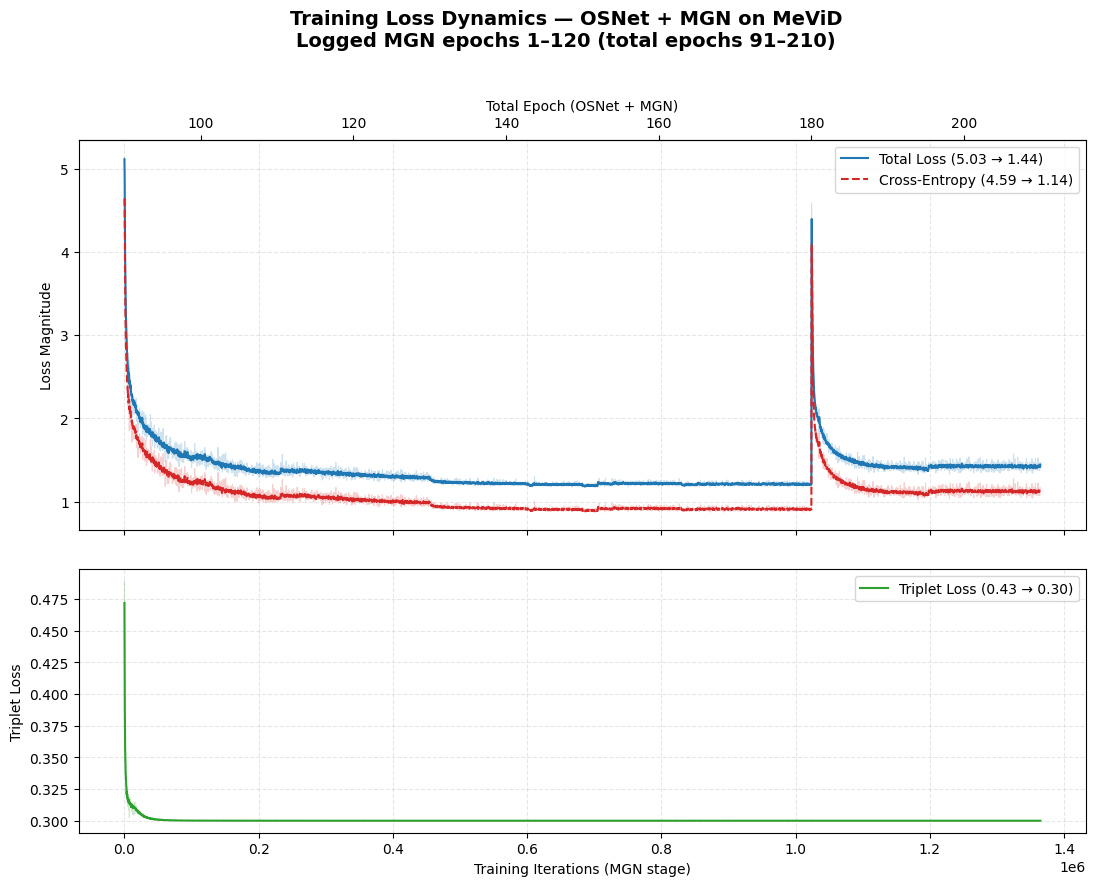

Total loss decreased by 71.40%: 5.0340 → 1.4397
Records plotted: 68,340 | Source: /kaggle/input/datasets/qimatx/last-checkpoint/metrics_history.jsonl
Figure saved: /kaggle/working/result_mgn/training_loss_dynamics.png


In [17]:
# Training loss dynamics from metrics_history.jsonl
# This cell only reads logs; it does not train or evaluate the model.

import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import MaxNLocator

HISTORY_FILE = "/kaggle/input/datasets/qimatx/last-checkpoint/metrics_history.jsonl"  # Optional: full path to a metrics_history.jsonl from another session.
PLOT_SMOOTH_WINDOW = 15

output_dir = Path(globals().get("OUT", "/kaggle/working/result_mgn"))
if HISTORY_FILE:
    history_path = Path(HISTORY_FILE).expanduser()
else:
    history_path = output_dir / "metrics_history.jsonl"

if not history_path.is_file():
    raise FileNotFoundError(
        f"Training log not found: {history_path}. "
        "Set HISTORY_FILE to a valid metrics_history.jsonl path."
    )

records = {}
with history_path.open("r", encoding="utf-8") as handle:
    for line in handle:
        if not line.strip():
            continue
        try:
            item = json.loads(line)
            step = int(item["iteration"])
            row = {name: float(item[name]) for name in
                   ("total_loss", "loss_cls", "loss_triplet")}
            row["iteration"] = step + 1
            records[step] = row  # Prefer the most recent record for a resumed iteration.
        except (ValueError, TypeError, KeyError, json.JSONDecodeError):
            continue  # Ignore health-only lines and incomplete JSON records.

if not records:
    raise RuntimeError(
        "No complete loss records found (requires total_loss, loss_cls, loss_triplet)."
    )

history = pd.DataFrame(records.values()).sort_values("iteration")
history = history.replace([float("inf"), float("-inf")], float("nan"))
history = history.dropna(subset=["total_loss", "loss_cls", "loss_triplet"])
if history.empty:
    raise RuntimeError("All parsed loss values are invalid.")

state_path = output_dir / "training_state.json"
state = json.loads(state_path.read_text(encoding="utf-8")) if state_path.is_file() else {}
active_trainer = globals().get("trainer")
steps_per_epoch = (
    getattr(active_trainer, "iters_per_epoch", None)
    or state.get("iters_per_epoch")
)
if not steps_per_epoch and "SPLITS" in globals() and "cfg" in globals():
    steps_per_epoch = len(SPLITS["train"]) // int(cfg.SOLVER.IMS_PER_BATCH)
if not steps_per_epoch:
    raise RuntimeError("Cannot identify steps_per_epoch from trainer or training_state.json.")
steps_per_epoch = int(steps_per_epoch)

prior_epochs = int(
    getattr(active_trainer, "source_completed_epochs", None)
    or state.get("source_completed_epochs", 0)
)
first_stage_epoch = (int(history["iteration"].min()) - 1) // steps_per_epoch + 1
last_stage_epoch = (int(history["iteration"].max()) - 1) // steps_per_epoch + 1

# Smooth the display only; do not modify original recorded losses.
window = max(1, int(PLOT_SMOOTH_WINDOW))
for key in ("total_loss", "loss_cls", "loss_triplet"):
    history[key + "_smooth"] = history[key].rolling(
        window=window, min_periods=1, center=True
    ).mean()

# Avoid rendering tens of thousands of points; summaries still use all records.
plot_stride = max(1, len(history) // 5000)
visible = history.iloc[::plot_stride]
x = visible["iteration"]

n_edge = min(20, max(1, len(history) // 10))
def edge_values(key):
    return (float(history[key].head(n_edge).median()),
            float(history[key].tail(n_edge).median()))

fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, figsize=(13, 9), sharex=True,
    gridspec_kw={"height_ratios": [2, 1.35], "hspace": 0.12}
)
colors = {"total_loss": "#1f77b4", "loss_cls": "#d62728", "loss_triplet": "#2ca02c"}

for key, label, axis, style in (
    ("total_loss", "Total Loss", ax_top, "-"),
    ("loss_cls", "Cross-Entropy", ax_top, "--"),
    ("loss_triplet", "Triplet Loss", ax_bottom, "-"),
):
    first, last = edge_values(key)
    axis.plot(x, visible[key], color=colors[key], alpha=0.22, linewidth=0.8)
    axis.plot(x, visible[key + "_smooth"], style, color=colors[key],
              linewidth=1.5, label=f"{label} ({first:.2f} → {last:.2f})")
    axis.legend(loc="best", fontsize=10)
    axis.grid(True, linestyle="--", alpha=0.3)
    axis.set_ylabel("Loss Magnitude" if axis is ax_top else "Triplet Loss")

ax_bottom.set_xlabel("Training Iterations (MGN stage)")
ax_bottom.xaxis.set_major_locator(MaxNLocator(nbins=8, integer=True))
if prior_epochs:
    secondary = ax_top.secondary_xaxis(
        "top", functions=(
            lambda it: prior_epochs + it / steps_per_epoch,
            lambda ep: (ep - prior_epochs) * steps_per_epoch,
        )
    )
    secondary.set_xlabel("Total Epoch (OSNet + MGN)")
else:
    secondary = ax_top.secondary_xaxis(
        "top", functions=(
            lambda it: it / steps_per_epoch,
            lambda ep: ep * steps_per_epoch,
        )
    )
    secondary.set_xlabel("Training Epoch")

fig.suptitle(
    "Training Loss Dynamics — OSNet + MGN on MeViD\n"
    f"Logged MGN epochs {first_stage_epoch}–{last_stage_epoch}"
    + (f" (total epochs {prior_epochs + first_stage_epoch}–{prior_epochs + last_stage_epoch})"
       if prior_epochs else ""),
    fontsize=14, fontweight="bold", y=1.025,
)
figure_path = output_dir / "training_loss_dynamics.png"
output_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()

first_total, last_total = edge_values("total_loss")
if first_total > 0:
    change_pct = (last_total - first_total) / first_total * 100
    direction = "decreased" if change_pct < 0 else "increased"
    print(f"Total loss {direction} by {abs(change_pct):.2f}%: {first_total:.4f} → {last_total:.4f}")
else:
    print(f"Total loss: {first_total:.4f} → {last_total:.4f}")
print(f"Records plotted: {len(history):,} | Source: {history_path}")
print(f"Figure saved: {figure_path}")
